# Notebook 04: Luật kết hợp theo cụm và gợi ý sản phẩm giữ chân khách hàng

**Mục tiêu của notebook:**

1. Tìm **luật kết hợp** (sản phẩm hay được mua cùng nhau) **riêng cho từng cụm khách hàng** bằng thuật toán **FP-Growth**, đối chiếu với **Apriori** (C3).
2. So sánh hành vi mua kèm giữa các cụm (VIP mua kèm gì, khác cụm Có nguy cơ thế nào).
3. **Gợi ý sản phẩm** (bán chéo, C1) cho các khách có nguy cơ rời bỏ cao (từ notebook 03), dựa trên sản phẩm khách đã mua: ưu tiên luật của cụm mà khách thuộc về, sau đó đến luật mua kèm của toàn cửa hàng, cuối cùng mới đến hàng bán chạy. **Mỗi gợi ý đều kèm lý do bằng lời.**
4. Tổng hợp **đề xuất chiến lược** cho từng cụm, kèm căn cứ số liệu cho từng hành động.

**Đầu vào:** `transactions_clean.csv`, `customers_clustered.csv`, `churn_predictions.csv`.
**Đầu ra:** `data/processed/rules_by_cluster.csv`, `data/processed/recommendations.csv`.

**Nhắc lại khái niệm** (C3): mỗi hóa đơn là một **giao dịch** (*transaction*), mỗi sản phẩm là một **item**, một tập sản phẩm là một **itemset**. Với luật A -> B:

- **Support** = tỷ lệ giao dịch chứa cả A và B = P(A ∪ B).
- **Confidence** = P(B | A) = support(A ∪ B) / support(A): trong các giao dịch có A, bao nhiêu % có B.
- Itemset là **phổ biến** (*frequent itemset*) nếu support ≥ `min_support`. Luật được giữ nếu sinh từ một itemset phổ biến và có confidence ≥ `min_confidence`.

**Cách trình bày:** mỗi mục gồm phần giải thích mục đích và cách làm, ô code, kết quả, phần **Cách đọc** (giải thích các cột của bảng hoặc các thành phần của biểu đồ) và phần **Nhận xét**.

## 0. Khai báo thư viện và tham số

Các tham số chính của notebook được khai báo ở ô code bên dưới. Nếu thay đổi tham số, cần chạy lại cả notebook và cập nhật các ô nhận xét.

| Tham số | Giá trị | Ý nghĩa |
|---|---|---|
| `BASE_MIN_SUPPORT` | 0,01 | Một tập sản phẩm phải có mặt trong ít nhất 1% số hóa đơn của cụm mới được coi là phổ biến |
| `MIN_INVOICES` | 20 | ... và trong ít nhất 20 hóa đơn (quan trọng với cụm nhỏ). Đây cũng là ngưỡng của luật toàn cửa hàng ở mục 5.2 |
| `MIN_CONFIDENCE` | 0,5 | Chỉ giữ luật A -> B nếu ít nhất 50% số hóa đơn có A cũng có B |
| `HIGH_RISK_QUANTILE` | 0,75 | Khách nguy cơ cao là 25% khách có xác suất churn cao nhất **trong cụm của mình** (từ phân vị 75%, tức tứ phân vị thứ ba Q3, C2) |
| `TOP_N` | 5 | Số sản phẩm gợi ý cho mỗi khách |

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", "{:,.3f}".format)

PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
REF_DATE = pd.Timestamp("2011-09-10")
CLUSTER_ORDER = ["VIP", "Khách mới", "Có nguy cơ", "Ngủ đông"]

BASE_MIN_SUPPORT = 0.01
MIN_INVOICES = 20
MIN_CONFIDENCE = 0.5

HIGH_RISK_QUANTILE = 0.75
TOP_N = 5
STORE_SCOPE = "Toàn cửa hàng"

In [2]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,
})


def save_fig(fig, filename):
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")


CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, COLORS[:4]))

## 1. Đọc dữ liệu và gắn nhãn cụm cho giao dịch

Chỉ dùng giao dịch **giai đoạn quan sát** (trước 10/09/2011) của các khách trong tập nghiên cứu, để luật kết hợp phản ánh đúng thông tin có được tại thời điểm ra quyết định. Mỗi giao dịch được gắn thêm tên cụm (`ClusterName`) của khách thực hiện giao dịch đó, để có thể khai phá luật riêng cho từng cụm.

In [3]:
transactions = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
customers = pd.read_csv(PROCESSED_DIR / "customers_clustered.csv")
predictions = pd.read_csv(PROCESSED_DIR / "churn_predictions.csv")

obs = transactions[transactions["InvoiceDate"] < REF_DATE].merge(
    customers[["CustomerID", "ClusterName"]], on="CustomerID", how="inner"
)
print(f"Giao dịch giai đoạn quan sát của tập nghiên cứu: {len(obs):,} dòng, {obs['CustomerID'].nunique():,} khách")

Giao dịch giai đoạn quan sát của tập nghiên cứu: 582,831 dòng, 4,299 khách


In [4]:
invoice_info = obs.groupby("Invoice").agg(ClusterName=("ClusterName", "first"),
                                          BasketSize=("Description", "nunique"))
cluster_overview = obs.groupby("ClusterName").agg(
    NumCustomers=("CustomerID", "nunique"),
    NumInvoices=("Invoice", "nunique"),
    NumProducts=("Description", "nunique"),
).reindex(CLUSTER_ORDER)
cluster_overview["AvgBasketSize"] = invoice_info.groupby("ClusterName")["BasketSize"].mean()
cluster_overview["InvoicesPerCustomer"] = cluster_overview["NumInvoices"] / cluster_overview["NumCustomers"]
cluster_overview.rename(columns={
    "NumCustomers": "Số khách", "NumInvoices": "Số hóa đơn", "NumProducts": "Số sản phẩm khác nhau",
    "AvgBasketSize": "Số sản phẩm TB / hóa đơn", "InvoicesPerCustomer": "Số hóa đơn TB / khách",
}).style.format({"Số khách": "{:,}", "Số hóa đơn": "{:,}", "Số sản phẩm khác nhau": "{:,}",
                 "Số sản phẩm TB / hóa đơn": "{:.1f}", "Số hóa đơn TB / khách": "{:.1f}"})

,Số khách,Số hóa đơn,Số sản phẩm khác nhau,Số sản phẩm TB / hóa đơn,Số hóa đơn TB / khách
ClusterName,,,,,
VIP,"1,284","19,087","4,291",20.7,14.9
Khách mới,947,"1,992","3,262",17.7,2.1
Có nguy cơ,947,"5,205","3,855",21.1,5.5
Ngủ đông,"1,121","1,806","3,148",19.7,1.6


**Cách đọc bảng:** mỗi dòng là một cụm.

- `Số sản phẩm khác nhau`: số sản phẩm mà khách trong cụm từng mua.
- `Số sản phẩm TB / hóa đơn`: số sản phẩm khác nhau trung bình trong một hóa đơn (kích thước giỏ hàng).
- `Số hóa đơn TB / khách`: số lần mua trung bình của một khách trong giai đoạn quan sát.

**Nhận xét:** - Số hóa đơn chênh lệch rất lớn giữa các cụm: VIP có 19.087 hóa đơn (khoảng 68% trong tổng số 28.090 hóa đơn, trung bình 14,9 hóa đơn mỗi khách), Có nguy cơ 5.205, trong khi Khách mới chỉ có 1.992 và Ngủ đông 1.806. Đây là lý do `min_support` cần được điều chỉnh theo kích thước cụm.
- Số sản phẩm trong mỗi hóa đơn lại **tương tự nhau** giữa các cụm (khoảng 18 đến 21 sản phẩm). Khác biệt giữa các cụm nằm ở **số lần mua**, không phải kích thước giỏ hàng. Giỏ hàng khoảng 20 sản phẩm là đặc trưng của khách sỉ.

## 2. Khai phá luật kết hợp theo từng cụm bằng FP-Growth (C3)

**Cách làm với mỗi cụm:**

1. **Ma trận giỏ hàng:** mỗi dòng là một hóa đơn (giao dịch), mỗi cột là một sản phẩm (`Description`), giá trị `True` nếu hóa đơn có sản phẩm đó.
2. **Chọn `min_support` theo kích thước cụm:** `min_support = max(1%, 20 / số hóa đơn của cụm)`. Với cụm lớn (VIP có hơn 19 nghìn hóa đơn), 1% đã tương ứng hơn 190 hóa đơn; với cụm nhỏ, điều kiện "ít nhất 20 hóa đơn" đảm bảo luật không được rút ra từ quá ít quan sát.
3. **Lọc trước sản phẩm hiếm:** theo **tính chất Apriori** (mọi tập con của một tập phổ biến cũng phổ biến; ngược lại, tập chứa một item không phổ biến thì không thể phổ biến), sản phẩm có support nhỏ hơn `min_support` không thể nằm trong tập phổ biến nào, nên bỏ trước để ma trận nhỏ gọn hơn. Lưu ý vẫn giữ **tất cả hóa đơn** (kể cả hóa đơn không còn sản phẩm nào sau khi lọc) để support được tính trên đúng tổng số hóa đơn.
4. Chạy **FP-Growth** tìm tập phổ biến, sinh luật bằng `association_rules(..., metric="confidence", min_threshold=0.5)`: chỉ giữ luật có **confidence ≥ 0,5**.

*Vì sao FP-Growth?* Apriori phải sinh tập ứng viên Cₖ từ Lₖ₋₁ và quét lại dữ liệu ở mỗi mức k để đếm support. FP-Growth chỉ quét dữ liệu 2 lần, nén các giao dịch vào cây **FP-tree** rồi khai phá đệ quy trên cây, không phải sinh ứng viên. Mục 2.1 so sánh trực tiếp hai thuật toán trên cùng dữ liệu.

In [5]:
def mine_rules(cluster_tx):
    invoices = cluster_tx["Invoice"].unique()
    n_invoices = len(invoices)
    min_support = max(BASE_MIN_SUPPORT, MIN_INVOICES / n_invoices)

    item_support = cluster_tx.groupby("Description")["Invoice"].nunique() / n_invoices
    frequent_items = item_support[item_support >= min_support].index
    tx = cluster_tx[cluster_tx["Description"].isin(frequent_items)]

    basket = pd.crosstab(tx["Invoice"], tx["Description"]).gt(0)
    basket = basket.reindex(invoices, fill_value=False)

    itemsets = fpgrowth(basket, min_support=min_support, use_colnames=True)
    rules = association_rules(itemsets, num_itemsets=n_invoices, metric="confidence", min_threshold=MIN_CONFIDENCE)
    return min_support, item_support.max(), basket, itemsets, rules

In [6]:
rule_frames = []
mining_summary = []
baskets = {}
for name in CLUSTER_ORDER:
    cluster_tx = obs[obs["ClusterName"] == name]
    min_support, max_item_support, basket, itemsets, rules = mine_rules(cluster_tx)
    baskets[name] = basket
    rules = rules.assign(ClusterName=name)
    rule_frames.append(rules)
    mining_summary.append({
        "ClusterName": name,
        "Số hóa đơn": cluster_tx["Invoice"].nunique(),
        "min_support": min_support,
        "Số sản phẩm đủ support": basket.shape[1],
        "Support lớn nhất của 1 sản phẩm": max_item_support,
        "Số tập phổ biến": len(itemsets),
        "Tập phổ biến dài nhất": itemsets["itemsets"].apply(len).max(),
        "Số luật": len(rules),
        "Support TB": rules["support"].mean(),
        "Confidence TB": rules["confidence"].mean(),
        "Confidence lớn nhất": rules["confidence"].max(),
    })
    print(f"{name:12s} min_support = {min_support:.4f} -> {len(itemsets):,} tập phổ biến, {len(rules):,} luật")

rules_all = pd.concat(rule_frames, ignore_index=True)
rules_all["Antecedents"] = rules_all["antecedents"].apply(lambda s: " + ".join(sorted(s)))
rules_all["Consequents"] = rules_all["consequents"].apply(lambda s: " + ".join(sorted(s)))
rules_all["Itemset"] = [a | c for a, c in zip(rules_all["antecedents"], rules_all["consequents"])]


def sort_rules(rules):
    return rules.sort_values(["confidence", "support", "Antecedents", "Consequents"],
                             ascending=[False, False, True, True])


rules_all = sort_rules(rules_all).sort_values("ClusterName", kind="stable").reset_index(drop=True)
print(f"Tổng số luật theo cụm: {len(rules_all):,}")

mining_summary = pd.DataFrame(mining_summary).set_index("ClusterName")
mining_summary.style.format({
    "Số hóa đơn": "{:,}", "min_support": "{:.4f}", "Support lớn nhất của 1 sản phẩm": "{:.3f}",
    "Số tập phổ biến": "{:,}", "Số luật": "{:,}", "Support TB": "{:.4f}", "Confidence TB": "{:.3f}",
    "Confidence lớn nhất": "{:.3f}",
})

VIP          min_support = 0.0100 -> 1,099 tập phổ biến, 520 luật


Khách mới    min_support = 0.0100 -> 661 tập phổ biến, 117 luật


Có nguy cơ   min_support = 0.0100 -> 1,011 tập phổ biến, 729 luật


Ngủ đông     min_support = 0.0111 -> 687 tập phổ biến, 123 luật
Tổng số luật theo cụm: 1,489


,Số hóa đơn,min_support,Số sản phẩm đủ support,Support lớn nhất của 1 sản phẩm,Số tập phổ biến,Tập phổ biến dài nhất,Số luật,Support TB,Confidence TB,Confidence lớn nhất
ClusterName,,,,,,,,,,
VIP,"19,087",0.0100,560,0.142,"1,099",4,520,0.0139,0.625,0.902
Khách mới,"1,992",0.0100,542,0.105,661,4,117,0.0145,0.655,0.915
Có nguy cơ,"5,205",0.0100,619,0.182,"1,011",6,729,0.0130,0.777,1.000
Ngủ đông,"1,806",0.0111,563,0.122,687,4,123,0.0159,0.681,0.967


**Cách đọc bảng:**

- `min_support`: ngưỡng support của cụm theo công thức ở trên (0,0100 nghĩa là 1% số hóa đơn).
- `Số sản phẩm đủ support`: số sản phẩm có mặt trong ít nhất `min_support` hóa đơn của cụm (tập phổ biến 1 phần tử L₁). Chỉ những sản phẩm này mới có thể xuất hiện trong luật.
- `Support lớn nhất của 1 sản phẩm`: tỷ lệ hóa đơn của sản phẩm phổ biến nhất trong cụm.
- `Số tập phổ biến`: số tập sản phẩm (kể cả tập chỉ có 1 sản phẩm) có support ≥ `min_support`. `Tập phổ biến dài nhất` là số sản phẩm của tập phổ biến lớn nhất.
- `Số luật`: số luật có confidence ≥ 0,5. Ba cột cuối là support trung bình, confidence trung bình và confidence lớn nhất của các luật đó.

**Nhận xét:** - Tổng cộng **1.489 luật**: Có nguy cơ 729, VIP 520, Ngủ đông 123, Khách mới 117. Cụm Có nguy cơ có nhiều luật nhất dù chỉ có 5.205 hóa đơn (VIP có 19.087); mục 3 cho thấy nguyên nhân là một bộ sản phẩm được một khách đặt lặp lại nhiều lần.
- Ngủ đông chỉ có 1.806 hóa đơn nên `min_support` được nâng lên 1,11% (tương ứng 20 hóa đơn); ba cụm còn lại dùng mức 1% (với Khách mới, 20 / 1.992 chỉ nhỉnh hơn 1% một chút).
- **Sản phẩm phổ biến nhất mỗi cụm chỉ có mặt trong 10,5% đến 18,2% số hóa đơn**, tức mọi sản phẩm đều có support nhỏ hơn 0,5. Vì vậy, với mọi luật A -> B được giữ, P(B | A) ≥ 0,5 > P(B): điều kiện lọc cũ "A làm tăng khả năng mua B" luôn được thỏa, nên **tập luật không đổi** so với trước khi bỏ điều kiện đó. Chỉ thứ tự luật thay đổi, vì giờ luật được sắp theo confidence.
- Confidence trung bình từ 0,63 (VIP) đến 0,78 (Có nguy cơ); support trung bình chỉ khoảng 1,3% đến 1,6%: mỗi luật áp dụng cho một phần nhỏ hóa đơn nhưng khá chắc chắn. Tập phổ biến dài nhất gồm 4 sản phẩm (6 sản phẩm ở Có nguy cơ).

### 2.1. So sánh Apriori và FP-Growth (C3)

Với mỗi cụm, chạy thêm **Apriori** (`mlxtend.frequent_patterns.apriori`) với cùng `min_support` trên **cùng ma trận giỏ hàng**, rồi:

- Kiểm tra hai thuật toán cho ra **cùng tập phổ biến** (so sánh tập các `frozenset`) và cùng support.
- Đo thời gian chạy của mỗi thuật toán bằng `time.perf_counter()`.

Apriori được chạy với `low_memory=True` (đếm support của từng ứng viên lần lượt), vì cách đếm mặc định của thư viện tạo cùng lúc một mảng (số hóa đơn × số ứng viên), quá lớn với cụm VIP. Thời gian chạy phụ thuộc vào máy, nên chỉ so sánh tương đối giữa hai thuật toán; con số cụ thể có thể khác nhẹ giữa các lần chạy.

In [7]:
algo_rows = []
for name in CLUSTER_ORDER:
    basket = baskets[name]
    min_support = mining_summary.loc[name, "min_support"]

    start = time.perf_counter()
    fp_sets = fpgrowth(basket, min_support=min_support, use_colnames=True)
    fp_seconds = time.perf_counter() - start

    start = time.perf_counter()
    ap_sets = apriori(basket, min_support=min_support, use_colnames=True, low_memory=True)
    ap_seconds = time.perf_counter() - start

    fp_support = dict(zip(fp_sets["itemsets"], fp_sets["support"]))
    ap_support = dict(zip(ap_sets["itemsets"], ap_sets["support"]))
    same_sets = set(fp_support) == set(ap_support)
    algo_rows.append({
        "ClusterName": name,
        "Số hóa đơn × số sản phẩm": f"{basket.shape[0]:,} × {basket.shape[1]:,}",
        "Tập phổ biến (FP-Growth)": len(fp_support),
        "Tập phổ biến (Apriori)": len(ap_support),
        "Cùng tập phổ biến": "Có" if same_sets else "Không",
        "Chênh lệch support lớn nhất": max(abs(fp_support[s] - ap_support[s]) for s in fp_support) if same_sets else np.nan,
        "Thời gian FP-Growth (giây)": fp_seconds,
        "Thời gian Apriori (giây)": ap_seconds,
    })

algo_compare = pd.DataFrame(algo_rows).set_index("ClusterName")
algo_compare["Tỷ số thời gian FP-Growth / Apriori"] = (algo_compare["Thời gian FP-Growth (giây)"]
                                                      / algo_compare["Thời gian Apriori (giây)"])
algo_compare.style.format({"Tập phổ biến (FP-Growth)": "{:,}", "Tập phổ biến (Apriori)": "{:,}",
                           "Chênh lệch support lớn nhất": "{:.1e}", "Thời gian FP-Growth (giây)": "{:.2f}",
                           "Thời gian Apriori (giây)": "{:.2f}", "Tỷ số thời gian FP-Growth / Apriori": "{:.0f}"})

,Số hóa đơn × số sản phẩm,Tập phổ biến (FP-Growth),Tập phổ biến (Apriori),Cùng tập phổ biến,Chênh lệch support lớn nhất,Thời gian FP-Growth (giây),Thời gian Apriori (giây),Tỷ số thời gian FP-Growth / Apriori
ClusterName,,,,,,,,
VIP,"19,087 × 560","1,099","1,099",Có,0.0e+00,18.18,0.77,24
Khách mới,"1,992 × 542",661,661,Có,0.0e+00,0.55,0.04,13
Có nguy cơ,"5,205 × 619","1,011","1,011",Có,0.0e+00,4.01,0.12,33
Ngủ đông,"1,806 × 563",687,687,Có,0.0e+00,0.57,0.04,13


**Cách đọc:** `Số hóa đơn × số sản phẩm` là kích thước ma trận giỏ hàng sau khi lọc sản phẩm hiếm. `Chênh lệch support lớn nhất` bằng 0 nghĩa là mọi tập phổ biến có cùng support ở hai thuật toán. Cột cuối là thời gian của FP-Growth chia cho thời gian của Apriori.

**Nhận xét:** - **Hai thuật toán cho cùng một kết quả** ở cả 4 cụm: cùng tập các itemset phổ biến, cùng support. Đây là điều đúng theo lý thuyết (C3): Apriori và FP-Growth chỉ khác cách tìm, không khác định nghĩa tập phổ biến.
- **Về thời gian, kết quả ngược với lý thuyết:** trong thư viện `mlxtend`, FP-Growth chậm hơn Apriori nhiều lần (với VIP, FP-Growth mất khoảng 18 giây, Apriori dưới 1 giây). Lý do:
  - Ưu điểm của FP-Growth (không sinh ứng viên, chỉ quét dữ liệu 2 lần) chỉ thể hiện khi Apriori phải sinh **rất nhiều ứng viên**, tức khi `min_support` thấp và có nhiều tập phổ biến dài. Ở đây sản phẩm hiếm đã được lọc trước, chỉ còn khoảng 550 đến 620 sản phẩm, khoảng 700 đến 1.100 tập phổ biến và tập dài nhất chỉ 4 đến 6 sản phẩm, nên số ứng viên của Apriori nhỏ.
  - Cài đặt của `mlxtend` đếm support của ứng viên Apriori bằng phép toán vector trên ma trận (rất nhanh), trong khi FP-Growth xây cây và khai phá đệ quy bằng Python thuần.
- Ngược lại, ở mục 5.2, khi ngưỡng support giảm xuống dưới 0,1% trên toàn bộ hóa đơn, số tập phổ biến bùng nổ và FP-Growth chạy hơn 10 phút chưa xong; Apriori ở mức đó còn phải sinh nhiều ứng viên hơn. Vì kết quả hai thuật toán giống hệt nhau, notebook giữ FP-Growth làm thuật toán chính như thiết kế ban đầu.

## 3. Top luật của từng cụm (theo confidence)

**Cách đọc một dòng của bảng:** luật `Antecedents -> Consequents` (vế trái -> vế phải) có nghĩa là "hóa đơn có các sản phẩm ở vế trái thì thường có cả các sản phẩm ở vế phải". Khi một vế có nhiều sản phẩm, các sản phẩm được nối bằng dấu `+`.

- `support`: tỷ lệ hóa đơn của cụm chứa **đồng thời** mọi sản phẩm ở hai vế.
- `confidence`: trong các hóa đơn có vế trái, tỷ lệ hóa đơn có cả vế phải.

Mỗi cặp sản phẩm thường sinh ra hai luật theo hai chiều (A -> B và B -> A) với cùng support nhưng confidence khác nhau. Để bảng gọn hơn, mỗi bộ sản phẩm chỉ hiển thị **một chiều có confidence cao hơn**.

Luật được sắp theo confidence giảm dần; khi bằng nhau thì theo support giảm dần, rồi theo tên sản phẩm ở vế trái và vế phải (thứ tự chữ cái). Sản phẩm cũng được xếp theo support rồi theo tên. Nhờ các tiêu chí phụ này, thứ tự luật và danh sách gợi ý **không thay đổi giữa các lần chạy** (thư viện trả về tập sản phẩm dưới dạng `frozenset`, vốn không có thứ tự cố định).

Sau các bảng là phần **diễn giải bằng lời** luật mạnh nhất của mỗi cụm. Cách diễn giải này cũng được dùng để viết lý do cho từng gợi ý sản phẩm ở mục 5.

In [8]:
RULE_COLUMNS = ["Antecedents", "Consequents", "support", "confidence"]


def top_rules(cluster_name, n=10):
    r = sort_rules(rules_all[rules_all["ClusterName"] == cluster_name]).drop_duplicates("Itemset")
    return r.head(n).reset_index(drop=True)


for name in CLUSTER_ORDER:
    print(f"\n=== Cụm {name} ===")
    display(top_rules(name)[RULE_COLUMNS].style.format({"support": "{:.3f}", "confidence": "{:.2f}"}))


=== Cụm VIP ===


,Antecedents,Consequents,support,confidence
0,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.016,0.90
1,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.011,0.90
2,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,GREEN REGENCY TEACUP AND SAUCER,0.010,0.89
3,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,0.010,0.87
4,SET/20 RED RETROSPOT PAPER NAPKINS + SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.013,0.87
5,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.86
6,GREEN REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,0.012,0.86
7,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BEDROOM,0.010,0.85
8,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.018,0.84
9,SET/10 BLUE SPOTTY PARTY CANDLES,SET/10 PINK POLKADOT PARTY CANDLES,0.014,0.83



=== Cụm Khách mới ===


,Antecedents,Consequents,support,confidence
0,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.022,0.91
1,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.027,0.89
2,KITCHEN METAL SIGN,BATHROOM METAL SIGN,0.011,0.88
3,SET/10 BLUE SPOTTY PARTY CANDLES + SET/10 RED POLKADOT PARTY CANDLES,SET/10 PINK POLKADOT PARTY CANDLES,0.010,0.87
4,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER + ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.013,0.86
5,TOILET METAL SIGN,BATHROOM METAL SIGN,0.013,0.86
6,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,GREEN REGENCY TEACUP AND SAUCER,0.016,0.84
7,CHILDRENS CUTLERY SPACEBOY,CHILDRENS CUTLERY DOLLY GIRL,0.014,0.82
8,MAGIC DRAWING SLATE DOLLY GIRL,MAGIC DRAWING SLATE SPACEBOY,0.011,0.81
9,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.013,0.81



=== Cụm Có nguy cơ ===


,Antecedents,Consequents,support,confidence
0,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
1,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH + WOOD S/3 CABINET ANT WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
2,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH + WOODEN PICTURE FRAME WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
3,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH + WOOD S/3 CABINET ANT WHITE FINISH + WOODEN PICTURE FRAME WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
4,EDWARDIAN PARASOL RED + WHITE HANGING HEART T-LIGHT HOLDER + WOOD S/3 CABINET ANT WHITE FINISH,WOODEN PICTURE FRAME WHITE FINISH,0.011,1.00
5,EDWARDIAN PARASOL RED + WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH,0.011,1.00
6,EDWARDIAN PARASOL RED + WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH + WOODEN FRAME ANTIQUE WHITE,0.011,1.00
7,EDWARDIAN PARASOL RED + WOOD 2 DRAWER CABINET WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.011,1.00
8,EDWARDIAN PARASOL RED + WOODEN PICTURE FRAME WHITE FINISH,WHITE HANGING HEART T-LIGHT HOLDER,0.011,1.00
9,EDWARDIAN PARASOL RED + WOODEN PICTURE FRAME WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH,0.011,1.00



=== Cụm Ngủ đông ===


,Antecedents,Consequents,support,confidence
0,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.016,0.97
1,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.018,0.94
2,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.017,0.94
3,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE LIVINGROOM,0.017,0.94
4,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE KITCHEN,0.019,0.92
5,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE LIVINGROOM,0.019,0.92
6,POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.021,0.88
7,TOILET METAL SIGN,BATHROOM METAL SIGN,0.012,0.88
8,PINK 3 PIECE MINI DOTS CUTLERY SET + RED 3 PIECE MINI DOTS CUTLERY SET,BLUE 3 PIECE MINI DOTS CUTLERY SET,0.012,0.88
9,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE BEDROOM,0.018,0.86


In [9]:
invoice_counts = obs.groupby("ClusterName")["Invoice"].nunique()


def vn_number(x, decimals=0):
    return f"{x:,.{decimals}f}".replace(",", " ").replace(".", ",").replace(" ", ".")


def pct(x):
    return vn_number(100 * x, 1) + "%"


def join_names(items):
    items = sorted(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " và " + items[-1]


def explain_rule(rule):
    left, right = rule["antecedents"], rule["consequents"]
    if_part = join_names(left) if len(left) == 1 else "đủ " + join_names(left)
    then_part = join_names(right) if len(right) == 1 else "cả " + join_names(right)
    n_both = round(rule["support"] * invoice_counts[rule["ClusterName"]])
    if rule["ClusterName"] == STORE_SCOPE:
        where, base = "Trên toàn cửa hàng (mọi cụm)", "của cửa hàng"
    else:
        where, base = f"Trong cụm {rule['ClusterName']}", "của cụm"
    return (f"{where}, {pct(rule['confidence'])} hóa đơn có {if_part} cũng có {then_part} (confidence). "
            f"Có {vn_number(n_both)} hóa đơn chứa đồng thời các sản phẩm này, "
            f"chiếm {pct(rule['support'])} số hóa đơn {base} (support).")


lines = ["Diễn giải luật mạnh nhất (confidence cao nhất) của mỗi cụm:", ""]
for name in CLUSTER_ORDER:
    best = top_rules(name, n=1).iloc[0]
    lines += [f"- {name}: {best['Antecedents']} -> {best['Consequents']}", f"  {explain_rule(best)}", ""]
print("\n".join(lines))

Diễn giải luật mạnh nhất (confidence cao nhất) của mỗi cụm:

- VIP: PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER
  Trong cụm VIP, 90,2% hóa đơn có đủ PINK REGENCY TEACUP AND SAUCER và ROSES REGENCY TEACUP AND SAUCER cũng có GREEN REGENCY TEACUP AND SAUCER (confidence). Có 303 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,6% số hóa đơn của cụm (support).

- Khách mới: PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER
  Trong cụm Khách mới, 91,5% hóa đơn có đủ PINK REGENCY TEACUP AND SAUCER và ROSES REGENCY TEACUP AND SAUCER cũng có GREEN REGENCY TEACUP AND SAUCER (confidence). Có 43 hóa đơn chứa đồng thời các sản phẩm này, chiếm 2,2% số hóa đơn của cụm (support).

- Có nguy cơ: EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH -> WOODEN FRAME ANTIQUE WHITE
  Trong cụm Có nguy cơ, 100,0% hóa đơn có đủ EDWARDIAN PARASOL BLACK và WOOD 2 DRAWER CABINET WHITE FINISH cũng có 

In [10]:
cluster_invoices = (obs.groupby(["ClusterName", "Invoice"])
                    .agg(Items=("Description", set), CustomerID=("CustomerID", "first")).reset_index())
basis_rows = []
for name in CLUSTER_ORDER:
    best = top_rules(name, n=1).iloc[0]
    part = cluster_invoices[cluster_invoices["ClusterName"] == name]
    matched = part[[best["Itemset"] <= items for items in part["Items"]]]
    top_customer = matched["CustomerID"].value_counts()
    basis_rows.append({
        "Cụm": name,
        "Luật mạnh nhất": f"{best['Antecedents']} -> {best['Consequents']}",
        "Số hóa đơn chứa cả hai vế": len(matched),
        "Số khách khác nhau": matched["CustomerID"].nunique(),
        "Khách đóng góp nhiều hóa đơn nhất": int(top_customer.index[0]),
        "Tỷ trọng hóa đơn của khách đó": top_customer.iloc[0] / len(matched),
    })
pd.DataFrame(basis_rows).set_index("Cụm").style.format({"Tỷ trọng hóa đơn của khách đó": "{:.1%}"})

,Luật mạnh nhất,Số hóa đơn chứa cả hai vế,Số khách khác nhau,Khách đóng góp nhiều hóa đơn nhất,Tỷ trọng hóa đơn của khách đó
Cụm,,,,,
VIP,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER,303,155,14911,5.0%
Khách mới,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER,43,40,15215,4.7%
Có nguy cơ,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH -> WOODEN FRAME ANTIQUE WHITE,68,2,17850,98.5%
Ngủ đông,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE KITCHEN -> POPPY'S PLAYHOUSE LIVINGROOM,29,29,14269,3.4%


**Cách đọc bảng cuối:** với luật mạnh nhất của mỗi cụm, đếm số hóa đơn chứa đủ các sản phẩm ở hai vế, số khách khác nhau đứng sau các hóa đơn đó, và khách đóng góp nhiều hóa đơn nhất.

**Nhận xét:** - Hầu hết luật có confidence cao là **các biến thể của cùng một dòng sản phẩm**: khác màu (tách trà REGENCY xanh, hồng, hoa hồng; nến tiệc PARTY CANDLES xanh, hồng; dây cờ HAPPY BIRTHDAY BUNTING), khác mẫu (bộ dao nĩa trẻ em DOLLY GIRL / SPACEBOY, bảng MAGIC DRAWING SLATE), hoặc các phần của một bộ sưu tập (POPPY'S PLAYHOUSE phòng khách, phòng ngủ, bếp, phòng tắm; biển METAL SIGN nhà bếp, phòng tắm, toilet).
- Ý nghĩa kinh doanh: khách hàng (phần lớn là cửa hàng bán lẻ) thường **nhập đủ bộ, đủ màu** để trưng bày. Ví dụ: 90,2% hóa đơn VIP có đủ tách trà REGENCY hồng và hoa hồng cũng có tách màu xanh; ở Ngủ đông, 96,7% hóa đơn có 3 phòng của POPPY'S PLAYHOUSE cũng có phòng thứ tư. Đây là cơ hội cho gợi ý dạng **"hoàn thiện bộ sưu tập"**.
- **Cảnh báo với cụm Có nguy cơ:** các luật có confidence 100% (EDWARDIAN PARASOL, tủ gỗ WOOD CABINET, khung ảnh WOODEN FRAME) gần như chỉ đến từ **một khách**: 67 trong 68 hóa đơn chứa luật mạnh nhất là của khách 17850, người đặt lặp lại cùng một bộ hàng. Support được tính theo số hóa đơn, nên một khách mua rất nhiều lần có thể tự tạo ra cả một nhóm luật. Với VIP, Khách mới và Ngủ đông, luật mạnh nhất đến từ nhiều khách khác nhau (bảng cuối), nên đáng tin hơn.
- Những luật này có vẻ "hiển nhiên" với người trong ngành, nhưng vẫn hữu ích cho gợi ý tự động vì xác suất mua kèm cao và áp dụng được cho hàng nghìn khách cùng lúc.

### 3.1. Trực quan hóa các luật

Biểu đồ giúp nhìn toàn bộ luật của mỗi cụm cùng lúc, thay vì chỉ 10 luật đứng đầu.

**Cách đọc:** mỗi chấm là một luật, tô theo màu của cụm. Trục ngang là support (luật áp dụng cho bao nhiêu phần trăm hóa đơn), trục dọc là confidence (luật chắc chắn đến đâu). Luật lý tưởng để gợi ý nằm ở phía trên, càng về bên phải càng tốt.

Đã lưu: figures/04_luat_theo_cum.png


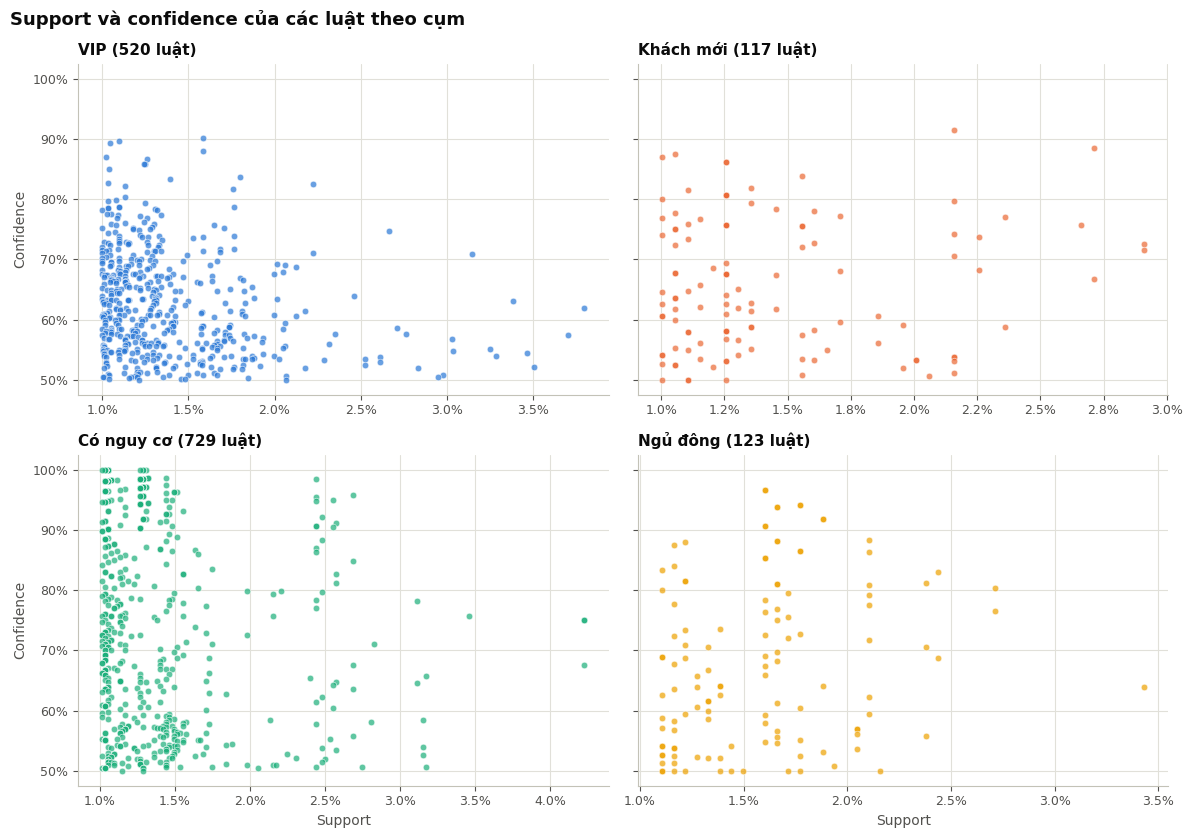

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True)
for ax, name in zip(axes.ravel(), CLUSTER_ORDER):
    r = rules_all[rules_all["ClusterName"] == name]
    ax.scatter(r["support"], r["confidence"], color=CLUSTER_COLORS[name], s=22, alpha=0.7,
               edgecolor="white", linewidth=0.5)
    ax.set_title(f"{name} ({len(r):,} luật)", fontsize=11)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
    ax.grid(axis="x", visible=True)
for ax in axes[1]:
    ax.set_xlabel("Support")
for ax in axes[:, 0]:
    ax.set_ylabel("Confidence")
fig.suptitle("Support và confidence của các luật theo cụm", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_luat_theo_cum.png")
plt.show()

**Nhận xét:** - Phần lớn luật có support chỉ từ 1% đến 2% số hóa đơn: mỗi luật áp dụng cho một phần nhỏ hóa đơn, vì cửa hàng có hơn 4.000 sản phẩm và giỏ hàng trải rộng trên nhiều sản phẩm khác nhau. Chỉ vài luật vượt 3%.
- Không có quan hệ rõ giữa support và confidence: luật có confidence rất cao (trên 90%) thường có support thấp, vì đó là các bộ sản phẩm hẹp mà ai mua một món thì gần như mua cả bộ.
- Cụm Có nguy cơ có một dải dày đặc các luật confidence 90% đến 100% ở support khoảng 1% đến 1,5% và 2,5%: đây là các tổ hợp con của cùng một bộ hàng do khách 17850 đặt lặp lại (mục 3).

## 4. So sánh luật giữa các cụm

### 4.1. Số luật chung và số luật riêng giữa các cụm

Hai luật được coi là **giống nhau** nếu có cùng vế trái và cùng vế phải. Với mỗi cặp cụm, đếm số luật xuất hiện ở cả hai cụm.

**Cách đọc:** ô ở hàng A, cột B của bảng thứ nhất là số luật chung của cụm A và cụm B; đường chéo là tổng số luật của cụm. Bảng thứ hai cho biết mỗi cụm có bao nhiêu luật, bao nhiêu luật trong số đó không xuất hiện ở bất kỳ cụm nào khác, và tỷ lệ tương ứng.

In [12]:
rule_keys = {
    name: set(zip(g["Antecedents"], g["Consequents"]))
    for name, g in rules_all.groupby("ClusterName")
}
common_rules = pd.DataFrame(
    [[len(rule_keys[a] & rule_keys[b]) for b in CLUSTER_ORDER] for a in CLUSTER_ORDER],
    index=CLUSTER_ORDER, columns=CLUSTER_ORDER,
)
print("Số luật chung giữa từng cặp cụm (đường chéo: tổng số luật của cụm):")
display(common_rules)

unique_counts = {
    name: len(rule_keys[name] - set().union(*(rule_keys[o] for o in CLUSTER_ORDER if o != name)))
    for name in CLUSTER_ORDER
}
own_rules = pd.DataFrame({"Số luật": {n: len(rule_keys[n]) for n in CLUSTER_ORDER},
                          "Số luật chỉ có ở cụm này": unique_counts})
own_rules["% luật riêng"] = own_rules["Số luật chỉ có ở cụm này"] / own_rules["Số luật"]
own_rules.style.format({"% luật riêng": "{:.1%}"})

Số luật chung giữa từng cặp cụm (đường chéo: tổng số luật của cụm):


,VIP,Khách mới,Có nguy cơ,Ngủ đông
VIP,520,62,147,52
Khách mới,62,117,57,38
Có nguy cơ,147,57,729,72
Ngủ đông,52,38,72,123


,Số luật,Số luật chỉ có ở cụm này,% luật riêng
VIP,520,359,69.0%
Khách mới,117,43,36.8%
Có nguy cơ,729,555,76.1%
Ngủ đông,123,43,35.0%


### 4.2. Sản phẩm phổ biến và sản phẩm xuất hiện nhiều nhất trong luật của mỗi cụm

Hai bảng dưới đây giúp phân biệt **sản phẩm bán chạy** với **sản phẩm hay được mua kèm**.

**Cách đọc:**

- **Bảng thứ nhất:** 10 sản phẩm có mặt trong nhiều hóa đơn nhất của mỗi cụm. Con số trong ngoặc là tỷ lệ hóa đơn của cụm có sản phẩm đó (support của riêng sản phẩm). Đây cũng là danh sách dùng để bổ sung gợi ý ở mục 5 khi luật kết hợp không đủ.
- **Bảng thứ hai:** 10 sản phẩm xuất hiện (ở vế trái hoặc vế phải) trong nhiều luật nhất của mỗi cụm. Con số trong ngoặc là số luật. Sản phẩm xuất hiện trong nhiều luật là sản phẩm "trung tâm" của các combo.

In [13]:
product_support = (obs.groupby(["ClusterName", "Description"])["Invoice"].nunique()
                   .div(invoice_counts, level="ClusterName").rename("support").reset_index())

top_products = {}
for name in CLUSTER_ORDER:
    top = (product_support[product_support["ClusterName"] == name]
           .sort_values(["support", "Description"], ascending=[False, True]).head(10))
    top_products[name] = [f"{d} ({s:.1%})" for d, s in zip(top["Description"], top["support"])]
print("Top 10 sản phẩm phổ biến nhất (tỷ lệ hóa đơn có sản phẩm) của từng cụm:")
display(pd.DataFrame(top_products, index=range(1, 11)))

top_rule_items = {}
for name in CLUSTER_ORDER:
    items = rules_all.loc[rules_all["ClusterName"] == name, "Itemset"].explode().value_counts()
    items = items.sort_index().sort_values(ascending=False, kind="stable").head(10)
    top_rule_items[name] = [f"{item} ({count})" for item, count in items.items()]
print("Top 10 sản phẩm xuất hiện trong nhiều luật nhất (số luật) của từng cụm:")
display(pd.DataFrame(top_rule_items, index=range(1, 11)))

Top 10 sản phẩm phổ biến nhất (tỷ lệ hóa đơn có sản phẩm) của từng cụm:


,VIP,Khách mới,Có nguy cơ,Ngủ đông
1,WHITE HANGING HEART T-LIGHT HOLDER (14.2%),REGENCY CAKESTAND 3 TIER (10.5%),WHITE HANGING HEART T-LIGHT HOLDER (18.2%),WHITE HANGING HEART T-LIGHT HOLDER (12.2%)
2,JUMBO BAG RED RETROSPOT (10.7%),WHITE HANGING HEART T-LIGHT HOLDER (10.5%),REGENCY CAKESTAND 3 TIER (9.0%),REX CASH+CARRY JUMBO SHOPPER (8.5%)
3,REGENCY CAKESTAND 3 TIER (9.7%),ASSORTED COLOUR BIRD ORNAMENT (8.0%),ASSORTED COLOUR BIRD ORNAMENT (7.8%),REGENCY CAKESTAND 3 TIER (7.4%)
4,LUNCH BAG RED RETROSPOT (8.7%),BAKING SET 9 PIECE RETROSPOT (7.3%),JUMBO BAG RED RETROSPOT (7.8%),ASSORTED COLOUR BIRD ORNAMENT (6.6%)
5,PACK OF 72 RETROSPOT CAKE CASES (8.0%),PARTY BUNTING (7.1%),STRAWBERRY CERAMIC TRINKET BOX (7.2%),PAPER CHAIN KIT 50'S CHRISTMAS (6.6%)
6,ASSORTED COLOUR BIRD ORNAMENT (7.4%),REX CASH+CARRY JUMBO SHOPPER (6.4%),PACK OF 72 RETROSPOT CAKE CASES (6.9%),HEART OF WICKER LARGE (6.5%)
7,PARTY BUNTING (6.9%),NATURAL SLATE HEART CHALKBOARD (6.0%),REX CASH+CARRY JUMBO SHOPPER (6.8%),PACK OF 72 RETROSPOT CAKE CASES (6.2%)
8,LUNCH BAG SUKI DESIGN (6.7%),PACK OF 72 RETROSPOT CAKE CASES (5.4%),HOME BUILDING BLOCK WORD (6.5%),NATURAL SLATE HEART CHALKBOARD (6.0%)
9,LUNCH BAG PINK POLKADOT (6.4%),HEART OF WICKER SMALL (5.0%),WOODEN FRAME ANTIQUE WHITE (6.3%),RETROSPOT TEA SET CERAMIC 11 PC (5.9%)
10,LUNCH BAG BLACK SKULL. (6.4%),6 RIBBONS RUSTIC CHARM (4.7%),LUNCH BAG RED RETROSPOT (6.1%),RED HANGING HEART T-LIGHT HOLDER (5.4%)


Top 10 sản phẩm xuất hiện trong nhiều luật nhất (số luật) của từng cụm:


,VIP,Khách mới,Có nguy cơ,Ngủ đông
1,LUNCH BAG RED RETROSPOT (144),GREEN REGENCY TEACUP AND SAUCER (26),WOODEN FRAME ANTIQUE WHITE (358),POPPY'S PLAYHOUSE LIVINGROOM (35)
2,LUNCH BAG SUKI DESIGN (110),PINK REGENCY TEACUP AND SAUCER (26),WOODEN PICTURE FRAME WHITE FINISH (356),POPPY'S PLAYHOUSE KITCHEN (34)
3,LUNCH BAG PINK POLKADOT (107),ROSES REGENCY TEACUP AND SAUCER (25),WOOD 2 DRAWER CABINET WHITE FINISH (346),POPPY'S PLAYHOUSE BATHROOM (33)
4,LUNCH BAG BLACK SKULL. (100),REGENCY CAKESTAND 3 TIER (21),WOOD S/3 CABINET ANT WHITE FINISH (345),POPPY'S PLAYHOUSE BEDROOM (33)
5,LUNCH BAG CARS BLUE (98),PLASTERS IN TIN SPACEBOY (8),WHITE HANGING HEART T-LIGHT HOLDER (270),BLUE 3 PIECE MINI DOTS CUTLERY SET (10)
6,LUNCH BAG SPACEBOY DESIGN (95),SET/10 BLUE SPOTTY PARTY CANDLES (8),EDWARDIAN PARASOL RED (259),PINK 3 PIECE MINI DOTS CUTLERY SET (10)
7,LUNCH BAG WOODLAND (78),SET/10 PINK POLKADOT PARTY CANDLES (8),EDWARDIAN PARASOL BLACK (69),RED 3 PIECE MINI DOTS CUTLERY SET (10)
8,JUMBO BAG RED RETROSPOT (64),SET/10 RED POLKADOT PARTY CANDLES (8),CREAM CUPID HEARTS COAT HANGER (68),GREEN REGENCY TEACUP AND SAUCER (5)
9,JUMBO BAG PINK POLKADOT (37),PLASTERS IN TIN CIRCUS PARADE (7),WHITE METAL LANTERN (20),PLASTERS IN TIN CIRCUS PARADE (5)
10,JUMBO STORAGE BAG SUKI (29),PLASTERS IN TIN WOODLAND ANIMALS (7),LUNCH BAG RED RETROSPOT (17),PLASTERS IN TIN WOODLAND ANIMALS (5)


### 4.3. So sánh trực tiếp VIP và Có nguy cơ

Hai cụm này cùng có lịch sử mua khá, khác nhau chủ yếu ở việc đã lâu chưa quay lại. Ta xem những luật mạnh chỉ có ở cụm này mà không có ở cụm kia. Bảng có cùng các cột và cùng cách đọc như ở mục 3.

In [14]:
def rules_only_in(cluster_a, cluster_b, n=8):
    r = rules_all[rules_all["ClusterName"] == cluster_a]
    mask = [key not in rule_keys[cluster_b] for key in zip(r["Antecedents"], r["Consequents"])]
    r = sort_rules(r[mask]).drop_duplicates("Itemset")
    return r.head(n)[RULE_COLUMNS].reset_index(drop=True)


fmt = {"support": "{:.3f}", "confidence": "{:.2f}"}
print("Luật mạnh có ở VIP nhưng không có ở Có nguy cơ:")
display(rules_only_in("VIP", "Có nguy cơ").style.format(fmt))
print("Luật mạnh có ở Có nguy cơ nhưng không có ở VIP:")
display(rules_only_in("Có nguy cơ", "VIP").style.format(fmt))

Luật mạnh có ở VIP nhưng không có ở Có nguy cơ:


,Antecedents,Consequents,support,confidence
0,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,GREEN REGENCY TEACUP AND SAUCER,0.010,0.89
1,PINK REGENCY TEACUP AND SAUCER + REGENCY CAKESTAND 3 TIER,ROSES REGENCY TEACUP AND SAUCER,0.010,0.87
2,SET/20 RED RETROSPOT PAPER NAPKINS + SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.013,0.87
3,BLUE STRIPE CERAMIC DRAWER KNOB + RED SPOT CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.010,0.83
4,LUNCH BAG PINK POLKADOT + LUNCH BAG SUKI DESIGN + LUNCH BAG WOODLAND,LUNCH BAG RED RETROSPOT,0.011,0.82
5,LUNCH BAG CARS BLUE + LUNCH BAG PINK POLKADOT + LUNCH BAG WOODLAND,LUNCH BAG RED RETROSPOT,0.011,0.80
6,LUNCH BAG PINK POLKADOT + LUNCH BAG SPACEBOY DESIGN + LUNCH BAG WOODLAND,LUNCH BAG RED RETROSPOT,0.011,0.80
7,LUNCH BAG BLACK SKULL. + LUNCH BAG PINK POLKADOT + LUNCH BAG WOODLAND,LUNCH BAG RED RETROSPOT,0.011,0.79


Luật mạnh có ở Có nguy cơ nhưng không có ở VIP:


,Antecedents,Consequents,support,confidence
0,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
1,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH + WOOD S/3 CABINET ANT WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
2,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH + WOODEN PICTURE FRAME WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
3,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH + WOOD S/3 CABINET ANT WHITE FINISH + WOODEN PICTURE FRAME WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.013,1.00
4,EDWARDIAN PARASOL RED + WHITE HANGING HEART T-LIGHT HOLDER + WOOD S/3 CABINET ANT WHITE FINISH,WOODEN PICTURE FRAME WHITE FINISH,0.011,1.00
5,EDWARDIAN PARASOL RED + WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH,0.011,1.00
6,EDWARDIAN PARASOL RED + WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH + WOODEN FRAME ANTIQUE WHITE,0.011,1.00
7,EDWARDIAN PARASOL RED + WOOD 2 DRAWER CABINET WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,0.011,1.00


**Nhận xét so sánh giữa các cụm:** - **Mỗi cụm có mẫu mua kèm khá riêng**: 69,0% luật của VIP và 76,1% luật của Có nguy cơ chỉ xuất hiện ở cụm đó. Cặp chung nhiều luật nhất là VIP và Có nguy cơ (147 luật chung), hợp lý vì cả hai đều là khách từng mua nhiều lần. Khách mới và Ngủ đông có ít luật hơn và khoảng 2/3 số luật của họ cũng xuất hiện ở cụm khác (chỉ 36,8% và 35,0% là luật riêng).
- **Sản phẩm chủ lực thì giống nhau** ở cả 4 cụm (WHITE HANGING HEART T-LIGHT HOLDER, REGENCY CAKESTAND 3 TIER, ASSORTED COLOUR BIRD ORNAMENT, PACK OF 72 RETROSPOT CAKE CASES). Khác biệt giữa các cụm nằm ở **cách mua kèm**, không phải ở sản phẩm bán chạy.
- **VIP**: luật xoay quanh **túi LUNCH BAG nhiều mẫu** (riêng LUNCH BAG RED RETROSPOT có mặt trong 144 luật) và túi JUMBO BAG, cùng các combo như bộ đồ tiệc giấy RED RETROSPOT (khăn ăn, cốc, đĩa) và núm tủ gốm DRAWER KNOB nhiều màu. VIP nhập hàng theo bộ lớn, mua "sâu" vào từng dòng sản phẩm.
- **Có nguy cơ**: luật bị chi phối bởi bộ đồ trang trí gỗ trắng (WOODEN FRAME ANTIQUE WHITE có mặt trong 358 luật) của khách 17850. Ngoài bộ này, các luật riêng của cụm là đồ làm vườn cho trẻ em, hộp cơm LUNCH BOX, túi JUMBO BAG.
- **Khách mới**: luật tập trung vào bộ tách trà REGENCY (xanh, hồng, hoa hồng) đi kèm REGENCY CAKESTAND, biển METAL SIGN, nến tiệc và hộp băng dán PLASTERS IN TIN. Khách mới thường bắt đầu với các sản phẩm "biểu tượng" của cửa hàng.
- **Ngủ đông**: luật chủ yếu là bộ POPPY'S PLAYHOUSE và bộ dao nĩa MINI DOTS; trong top sản phẩm có đồ Giáng sinh (PAPER CHAIN KIT 50'S CHRISTMAS đứng thứ 5), cho thấy nhiều khách ngủ đông là khách **mua theo mùa lễ**.

## 5. Gợi ý sản phẩm cho khách có nguy cơ rời bỏ cao

### 5.1. Chọn khách có nguy cơ cao

Như đã phân tích ở notebook 03, nếu dùng ngưỡng chung 0,5 thì gần như không có khách VIP nào được chọn (dù 21% VIP thực tế rời bỏ), còn gần như toàn bộ khách Ngủ đông bị chọn. Vì vậy ta chọn **25% khách có xác suất churn cao nhất trong từng cụm**, tức các khách có xác suất từ **phân vị 75% (tứ phân vị Q3, C2)** của cụm trở lên. Cách này giúp mỗi cụm đều có danh sách khách cần chăm sóc với quy mô hợp lý, và tận dụng khả năng **xếp hạng** của mô hình bên trong cụm.

In [15]:
threshold = predictions.groupby("ClusterName")["churn_proba"].transform(lambda s: s.quantile(HIGH_RISK_QUANTILE))
predictions["HighRisk"] = predictions["churn_proba"] >= threshold
high_risk = predictions[predictions["HighRisk"]].merge(customers[["CustomerID", "Monetary"]], on="CustomerID")

risk_summary = predictions.groupby("ClusterName").agg(
    NumCustomers=("CustomerID", "size"),
    ProbaThreshold=("churn_proba", lambda s: s.quantile(HIGH_RISK_QUANTILE)),
    ClusterChurnRate=("churn", "mean"),
).reindex(CLUSTER_ORDER)
risk_summary["NumHighRisk"] = high_risk.groupby("ClusterName").size()
risk_summary["HighRiskChurnRate"] = high_risk.groupby("ClusterName")["churn"].mean()
risk_summary["HighRiskMonetary"] = high_risk.groupby("ClusterName")["Monetary"].sum()
risk_summary.rename(columns={
    "NumCustomers": "Số khách", "ProbaThreshold": "Ngưỡng xác suất (phân vị 75%)",
    "ClusterChurnRate": "Tỷ lệ churn cả cụm", "NumHighRisk": "Số khách nguy cơ cao",
    "HighRiskChurnRate": "Tỷ lệ churn thực tế của nhóm được chọn",
    "HighRiskMonetary": "Tổng chi tiêu lịch sử của nhóm được chọn (£)",
}).style.format({
    "Số khách": "{:,}", "Ngưỡng xác suất (phân vị 75%)": "{:.3f}", "Tỷ lệ churn cả cụm": "{:.1%}",
    "Số khách nguy cơ cao": "{:,}", "Tỷ lệ churn thực tế của nhóm được chọn": "{:.1%}",
    "Tổng chi tiêu lịch sử của nhóm được chọn (£)": "{:,.0f}",
})

,Số khách,Ngưỡng xác suất (phân vị 75%),Tỷ lệ churn cả cụm,Số khách nguy cơ cao,Tỷ lệ churn thực tế của nhóm được chọn,Tổng chi tiêu lịch sử của nhóm được chọn (£)
ClusterName,,,,,,
VIP,"1,284",0.299,21.3%,321,43.0%,"680,315"
Khách mới,947,0.627,53.9%,237,70.5%,"69,496"
Có nguy cơ,947,0.613,52.8%,237,69.6%,"264,233"
Ngủ đông,"1,121",0.817,74.2%,281,85.4%,"51,298"


**Cách đọc bảng:**

- `Ngưỡng xác suất (phân vị 75%)`: khách có xác suất churn từ mức này trở lên thuộc nhóm 25% nguy cơ cao nhất của cụm.
- `Tỷ lệ churn cả cụm` và `Tỷ lệ churn thực tế của nhóm được chọn`: tính bằng nhãn thật, dùng để kiểm tra mô hình có chọn đúng những khách thực sự rời bỏ hay không.
- `Tổng chi tiêu lịch sử của nhóm được chọn`: tổng `Monetary` (giai đoạn quan sát) của các khách nguy cơ cao, tức giá trị có nguy cơ bị mất.

**Nhận xét:** - Mỗi cụm chọn 25% khách, tổng cộng **1.076 khách nguy cơ cao** (VIP 321, Khách mới 237, Có nguy cơ 237, Ngủ đông 281).
- Ngưỡng xác suất của từng cụm rất khác nhau, từ 0,30 (VIP) đến 0,82 (Ngủ đông). Điều này xác nhận dùng một ngưỡng chung cho mọi cụm là không phù hợp.
- Nhóm được chọn có **tỷ lệ churn thực tế cao hơn hẳn** mức chung của cụm: VIP 43,0% (gấp đôi 21,3%), Khách mới 70,5% (so với 53,9%), Có nguy cơ 69,6% (so với 52,8%), Ngủ đông 85,4% (so với 74,2%). Mô hình đã chọn đúng hướng. Vì xác suất của tập train là dự đoán out-of-fold, đánh giá này không bị lạc quan giả tạo.
- **Giá trị cần bảo vệ:** 321 khách VIP nguy cơ cao đã chi tổng cộng **£680K** trong giai đoạn quan sát, nhiều hơn cả nhóm nguy cơ cao của 3 cụm còn lại cộng lại (khoảng £385K). Đây là nhóm cần ưu tiên số một.

### 5.2. Luật mua kèm của toàn cửa hàng (dùng khi luật của cụm không đủ)

Luật của mỗi cụm chỉ được giữ khi xuất hiện trong ít nhất 1% số hóa đơn của cụm. Vì vậy nhiều sản phẩm ít phổ biến hơn không nằm trong luật nào, và những khách chỉ mua các sản phẩm đó (thường là khách mua ít, ở cụm Khách mới và Ngủ đông) không nhận được gợi ý nào từ luật của cụm.

Để vẫn gợi ý được **dựa trên sản phẩm khách đã mua**, ta tìm thêm luật mua kèm trên **toàn bộ hóa đơn** của giai đoạn quan sát (gộp mọi cụm):

- Chỉ xét luật một sản phẩm -> một sản phẩm (A -> B), tức chỉ cần các **2-itemset**.
- Giữ luật khi có ít nhất 20 hóa đơn chứa cả A và B (`MIN_INVOICES`) và confidence ≥ 0,5. Đây là cùng tiêu chuẩn với luật của cụm, chỉ bỏ điều kiện "ít nhất 1% số hóa đơn".
- **Cách đếm:** đây chính là bước đếm support của các **2-itemset ứng viên** trong Apriori (từ C₂ sinh ra L₂, C3). Với ma trận giỏ hàng B (hóa đơn × sản phẩm, giá trị 0/1), ô (a, b) của tích Bᵀ·B là số hóa đơn chứa cả a và b, tức support (dạng số đếm) của 2-itemset {a, b}; đường chéo là số hóa đơn của từng sản phẩm. Phép nhân được làm trên ma trận thưa (`scipy.sparse`) nên đếm được mọi cặp sản phẩm trong vài giây. Với ngưỡng thấp như vậy (20 trên khoảng 28 nghìn hóa đơn, tức chưa tới 0,1%), FP-Growth phải sinh rất nhiều tập phổ biến dài (khi thử nghiệm, chạy hơn 10 phút chưa xong), trong khi ta chỉ cần các cặp.

Luật của cụm vẫn được **ưu tiên trước**, vì phản ánh đúng hành vi của nhóm khách đó; luật toàn cửa hàng chỉ dùng để lấp các chỗ còn trống.

In [16]:
from scipy import sparse

invoice_product = obs[["Invoice", "Description"]].drop_duplicates()
invoice_idx, _ = pd.factorize(invoice_product["Invoice"])
product_idx, product_names = pd.factorize(invoice_product["Description"])
basket_all = sparse.csr_matrix((np.ones(len(invoice_product), dtype=np.int32), (invoice_idx, product_idx)))
n_invoices_all = basket_all.shape[0]
invoice_counts[STORE_SCOPE] = n_invoices_all

co_counts = (basket_all.T @ basket_all).tocoo()
product_counts = np.asarray(basket_all.sum(axis=0)).ravel()

store_rules = pd.DataFrame({"a": co_counts.row, "b": co_counts.col, "both": co_counts.data})
store_rules = store_rules[store_rules["a"] != store_rules["b"]]
store_rules["support"] = store_rules["both"] / n_invoices_all
store_rules["consequent support"] = product_counts[store_rules["b"]] / n_invoices_all
store_rules["confidence"] = store_rules["both"] / product_counts[store_rules["a"]]
store_rules = store_rules[(store_rules["both"] >= MIN_INVOICES)
                          & (store_rules["confidence"] >= MIN_CONFIDENCE)].copy()

store_rules["Antecedents"] = product_names[store_rules["a"]]
store_rules["Consequents"] = product_names[store_rules["b"]]
store_rules["antecedents"] = [frozenset([p]) for p in store_rules["Antecedents"]]
store_rules["consequents"] = [frozenset([p]) for p in store_rules["Consequents"]]
store_rules["ClusterName"] = STORE_SCOPE
store_rules = sort_rules(store_rules).reset_index(drop=True)

print(f"Luật toàn cửa hàng: {len(store_rules):,} luật, tính trên {n_invoices_all:,} hóa đơn, "
      f"vế trái gồm {store_rules['Antecedents'].nunique():,} sản phẩm khác nhau")
print(f"Số hóa đơn làm căn cứ: trung vị {store_rules['both'].median():.0f}, lớn nhất {store_rules['both'].max():,}")
print(f"So sánh: vế trái của luật theo 4 cụm chỉ gồm {rules_all['antecedents'].explode().nunique():,} sản phẩm khác nhau")
display(store_rules.head(10)[RULE_COLUMNS].style.format({"support": "{:.4f}", "confidence": "{:.2f}"}))

Luật toàn cửa hàng: 1,387 luật, tính trên 28,090 hóa đơn, vế trái gồm 839 sản phẩm khác nhau
Số hóa đơn làm căn cứ: trung vị 79, lớn nhất 916
So sánh: vế trái của luật theo 4 cụm chỉ gồm 192 sản phẩm khác nhau


,Antecedents,Consequents,support,confidence
0,SET/6 WOODLAND PAPER PLATES,SET/6 WOODLAND PAPER CUPS,0.0010,0.96
1,POPPY'S PLAYHOUSE BATHROOM,POPPY'S PLAYHOUSE KITCHEN,0.0092,0.93
2,HERB MARKER THYME,HERB MARKER ROSEMARY,0.0054,0.93
3,HERB MARKER CHIVES,HERB MARKER MINT,0.0048,0.93
4,HERB MARKER CHIVES,HERB MARKER PARSLEY,0.0048,0.93
5,HERB MARKER CHIVES,HERB MARKER THYME,0.0048,0.93
6,HERB MARKER PARSLEY,HERB MARKER MINT,0.0054,0.93
7,HERB MARKER PARSLEY,HERB MARKER ROSEMARY,0.0054,0.93
8,HERB MARKER CHIVES,HERB MARKER ROSEMARY,0.0048,0.92
9,HERB MARKER ROSEMARY,HERB MARKER THYME,0.0054,0.92


**Cách đọc bảng:** các cột giống bảng ở mục 3, nhưng support và confidence được tính trên toàn bộ hóa đơn của mọi cụm. Support ở đây rất nhỏ (khoảng 0,1% đến 1%) vì mẫu số là toàn bộ khoảng 28 nghìn hóa đơn.

**Nhận xét:** - Có **1.387 luật toàn cửa hàng**. Vế trái của các luật này gồm 839 sản phẩm khác nhau, gấp khoảng 4,4 lần so với 192 sản phẩm ở vế trái của luật theo cụm. Nhờ vậy, nhiều sản phẩm ít phổ biến hơn cũng có căn cứ để gợi ý mua kèm.
- Mỗi luật dựa trên ít nhất 20 hóa đơn (trung vị 79, nhiều nhất 916), nên dù support tính theo tỷ lệ rất nhỏ, số quan sát làm căn cứ vẫn đủ.
- Các luật có confidence cao nhất vẫn có dạng "cùng bộ, khác mẫu": đĩa và cốc giấy WOODLAND (96%), các phòng POPPY'S PLAYHOUSE, que cắm tên rau thơm HERB MARKER (thyme, rosemary, chives, mint, parsley, khoảng 92% đến 93%).

### 5.3. Thuật toán gợi ý

Với mỗi khách có nguy cơ cao, lấy tập sản phẩm khách **đã mua** trong giai đoạn quan sát, rồi điền 5 gợi ý lần lượt từ 3 nguồn:

1. **Luật của cụm** mà khách thuộc về, theo thứ tự confidence giảm dần. Nếu **vế trái** của luật nằm trọn trong tập sản phẩm khách đã mua, thì các sản phẩm ở **vế phải** mà khách **chưa mua** được đưa vào danh sách gợi ý.
2. Nếu chưa đủ 5 sản phẩm, dùng tiếp **luật toàn cửa hàng** (mục 5.2) theo đúng cách trên, cũng theo confidence giảm dần.
3. Nếu vẫn chưa đủ, bổ sung bằng **sản phẩm bán chạy nhất trong cụm** mà khách chưa mua. Đây là gợi ý theo độ phổ biến, **không dựa trên sản phẩm khách đã mua**, nên chỉ dùng khi không còn căn cứ nào khác.

**Lý do gợi ý (cột `Reason`).** Mỗi sản phẩm được gợi ý đều kèm một câu giải thích, để nhân viên bán hàng hoặc người đọc báo cáo hiểu vì sao sản phẩm được chọn:

- **Gợi ý từ luật** (của cụm hoặc của toàn cửa hàng): nêu sản phẩm khách đã mua (vế trái của luật), tỷ lệ hóa đơn có các sản phẩm đó cũng có sản phẩm được gợi ý (confidence), số hóa đơn chứa đồng thời các sản phẩm và tỷ lệ của chúng trên tổng số hóa đơn (support).
- **Gợi ý từ hàng bán chạy:** nêu cụ thể khách đã mua những gì và **vì sao** luật không cho đủ 5 gợi ý. Có đúng 3 trường hợp, được code xác định cho từng khách: không luật nào có vế trái nằm trọn trong các sản phẩm khách đã mua; có luật khớp nhưng các luật đó chỉ gợi ý sản phẩm khách đã có; hoặc luật chỉ cho được vài gợi ý. Sau đó nêu thứ hạng và độ phổ biến của sản phẩm trong cụm.

**Các cột của bảng gợi ý:**

| Cột | Ý nghĩa |
|---|---|
| `Rank` | Thứ tự ưu tiên trong 5 gợi ý của khách (1 là nên giới thiệu trước) |
| `RecommendedProduct` | Sản phẩm được gợi ý |
| `Source` | Nguồn gợi ý: `Luật của cụm`, `Luật toàn cửa hàng` hoặc `Bán chạy trong cụm` |
| `BasedOn` | Sản phẩm khách đã mua làm căn cứ (vế trái của luật); để trống nếu là hàng bán chạy |
| `Confidence`, `Support` | Chỉ số của luật được dùng; để trống nếu là hàng bán chạy |
| `Reason` | Lý do gợi ý, viết bằng lời |

In [17]:
customer_items = obs.groupby("CustomerID")["Description"].agg(set)

popular_items = {
    name: list(product_support[product_support["ClusterName"] == name]
               .sort_values(["support", "Description"], ascending=[False, True])
               .head(100)[["Description", "support"]].itertuples(index=False, name=None))
    for name in CLUSTER_ORDER
}

rules_lookup = {name: sort_rules(g).to_dict("records") for name, g in rules_all.groupby("ClusterName")}
store_lookup = store_rules.to_dict("records")

SOURCE_CLUSTER = "Luật của cụm"
SOURCE_STORE = "Luật toàn cửa hàng"
SOURCE_POPULAR = "Bán chạy trong cụm"
SOURCES = [SOURCE_CLUSTER, SOURCE_STORE, SOURCE_POPULAR]


def rule_recs(rules, bought, chosen, source, slots):
    recs, n_matched = [], 0
    for rule in rules:
        if len(recs) >= slots:
            break
        if rule["antecedents"] <= bought:
            n_matched += 1
            for item in sorted(rule["consequents"]):
                if item not in bought and item not in chosen:
                    chosen.add(item)
                    recs.append({"RecommendedProduct": item, "Source": source,
                                 "BasedOn": " + ".join(sorted(rule["antecedents"])),
                                 "Confidence": rule["confidence"], "Support": rule["support"],
                                 "Reason": f"Khách đã mua {join_names(rule['antecedents'])}. {explain_rule(rule)}"})
    return recs[:slots], n_matched


def fallback_reason(bought, n_from_rules, n_matched_rules):
    if len(bought) <= 5:
        what = f"Khách chỉ mua {len(bought)} sản phẩm ({join_names(bought)})"
    else:
        what = f"Khách đã mua {len(bought)} sản phẩm khác nhau"
    if n_from_rules > 0:
        return f"{what}; các luật mua kèm chỉ cho {n_from_rules} gợi ý, chưa đủ {TOP_N}."
    if n_matched_rules == 0:
        return (f"{what}, nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) "
                f"có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua.")
    return (f"{what}; có {n_matched_rules} luật khớp với các sản phẩm này, "
            f"nhưng các luật đó chỉ gợi ý những sản phẩm khách đã mua rồi.")


def recommend(customer_id, cluster_name, top_n=TOP_N):
    bought = customer_items[customer_id]
    chosen = set()
    recs, n_matched_cluster = rule_recs(rules_lookup.get(cluster_name, []), bought, chosen, SOURCE_CLUSTER, top_n)
    store_part, n_matched_store = rule_recs(store_lookup, bought, chosen, SOURCE_STORE, top_n - len(recs))
    recs += store_part

    if len(recs) < top_n:
        why = fallback_reason(bought, len(recs), n_matched_cluster + n_matched_store)
        for rank, (item, support) in enumerate(popular_items[cluster_name], start=1):
            if len(recs) >= top_n:
                break
            if item not in bought and item not in chosen:
                chosen.add(item)
                recs.append({"RecommendedProduct": item, "Source": SOURCE_POPULAR, "BasedOn": "",
                             "Confidence": np.nan, "Support": np.nan,
                             "Reason": (f"{why} Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ {rank} "
                                        f"của cụm {cluster_name} (có trong {pct(support)} hóa đơn của cụm) mà khách chưa mua. "
                                        f"Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua.")})
    return recs

In [18]:
rows = []
for customer in high_risk.itertuples(index=False):
    for rank, rec in enumerate(recommend(customer.CustomerID, customer.ClusterName), start=1):
        rows.append({"CustomerID": customer.CustomerID, "ClusterName": customer.ClusterName,
                     "churn_proba": customer.churn_proba, "Rank": rank, **rec})
recommendations = pd.DataFrame(rows)

rule_based = recommendations[recommendations["Source"] == SOURCE_CLUSTER]
any_rule = recommendations[recommendations["Source"].isin([SOURCE_CLUSTER, SOURCE_STORE])]
n_high_risk = high_risk.groupby("ClusterName").size()
coverage = pd.DataFrame({
    "Số khách nguy cơ cao": n_high_risk,
    "Có gợi ý từ luật của cụm": rule_based.groupby("ClusterName")["CustomerID"].nunique(),
    "Có gợi ý từ luật (cụm hoặc toàn cửa hàng)": any_rule.groupby("ClusterName")["CustomerID"].nunique(),
}).reindex(CLUSTER_ORDER).fillna(0).astype(int)
coverage["Chỉ nhận hàng bán chạy"] = coverage["Số khách nguy cơ cao"] - coverage["Có gợi ý từ luật (cụm hoặc toàn cửa hàng)"]
for col in ["Có gợi ý từ luật của cụm", "Có gợi ý từ luật (cụm hoặc toàn cửa hàng)", "Chỉ nhận hàng bán chạy"]:
    coverage[f"% {col.lower()}"] = coverage[col] / coverage["Số khách nguy cơ cao"]
print(f"Tổng số dòng gợi ý: {len(recommendations):,} cho {recommendations['CustomerID'].nunique():,} khách")
display(coverage.style.format({c: "{:.1%}" for c in coverage.columns if c.startswith("%")}))

slots_by_source = (recommendations.groupby(["ClusterName", "Source"]).size().unstack(fill_value=0)
                   .reindex(index=CLUSTER_ORDER, columns=SOURCES, fill_value=0))
print("Số gợi ý theo nguồn:")
slots_by_source

Tổng số dòng gợi ý: 5,380 cho 1,076 khách


,Số khách nguy cơ cao,Có gợi ý từ luật của cụm,Có gợi ý từ luật (cụm hoặc toàn cửa hàng),Chỉ nhận hàng bán chạy,% có gợi ý từ luật của cụm,% có gợi ý từ luật (cụm hoặc toàn cửa hàng),% chỉ nhận hàng bán chạy
ClusterName,,,,,,,
VIP,321,263,303,18,81.9%,94.4%,5.6%
Khách mới,237,79,165,72,33.3%,69.6%,30.4%
Có nguy cơ,237,175,217,20,73.8%,91.6%,8.4%
Ngủ đông,281,86,196,85,30.6%,69.8%,30.2%


Số gợi ý theo nguồn:


Source,Luật của cụm,Luật toàn cửa hàng,Bán chạy trong cụm
ClusterName,,,
VIP,904,441,260
Khách mới,139,368,678
Có nguy cơ,508,384,293
Ngủ đông,138,410,857


**Cách đọc bảng thứ nhất** (số khách):

- `Có gợi ý từ luật của cụm`: số khách nhận được ít nhất 1 gợi ý từ luật của cụm mình.
- `Có gợi ý từ luật (cụm hoặc toàn cửa hàng)`: số khách nhận được ít nhất 1 gợi ý dựa trên sản phẩm đã mua, từ bất kỳ loại luật nào.
- `Chỉ nhận hàng bán chạy`: số khách không có căn cứ mua kèm nào, nên cả 5 gợi ý đều là hàng bán chạy của cụm.
- Ba cột cuối là các tỷ lệ tương ứng, tính trên số khách nguy cơ cao của cụm.

**Bảng thứ hai** cho biết trong tổng số gợi ý của mỗi cụm (5 gợi ý × số khách), bao nhiêu gợi ý đến từ mỗi nguồn.

**Nhận xét:** - **Luật của cụm đủ cho phần lớn khách VIP (81,9%) và Có nguy cơ (73,8%)**, vì những khách này đã mua nhiều loại sản phẩm nên dễ khớp với vế trái của luật. Ngược lại, chỉ 33,3% khách Khách mới và 30,6% khách Ngủ đông nhận được gợi ý từ luật của cụm: họ mua ít loại sản phẩm, và cụm của họ cũng có ít luật.
- **Luật toàn cửa hàng lấp được phần lớn khoảng trống.** Nếu chỉ dùng luật của cụm, 473 trên 1.076 khách (44%) không có gợi ý nào dựa trên sản phẩm đã mua; khi thêm luật toàn cửa hàng, con số này giảm còn **195 khách (18%)**. Tỷ lệ khách có gợi ý theo sản phẩm đã mua tăng lên 94,4% ở VIP, 69,6% ở Khách mới, 91,6% ở Có nguy cơ và 69,8% ở Ngủ đông.
- 195 khách còn lại chủ yếu thuộc Ngủ đông (85 khách) và Khách mới (72 khách), là những khách mua ít loại sản phẩm. Những khách này chỉ có thể nhận gợi ý theo độ phổ biến. Đây là giới hạn tự nhiên của phương pháp luật kết hợp với khách có ít lịch sử mua.

### 5.4. Minh họa với một số khách cụ thể

Với mỗi cụm, chọn khách nguy cơ cao có **tổng chi tiêu lớn nhất** (khách giá trị nhất cần giữ), ưu tiên những khách nhận được từ 3 gợi ý dựa trên luật của cụm trở lên để minh họa rõ cách luật hoạt động.

**Cách đọc:** dòng tiêu đề tóm tắt hồ sơ của khách (xác suất churn, số ngày chưa mua, số hóa đơn, tổng chi tiêu, số sản phẩm đã mua). Bảng bên dưới là 5 gợi ý theo thứ tự ưu tiên, cột `Reason` giải thích lý do của từng gợi ý.

In [19]:
num_rule_recs = rule_based.groupby("CustomerID").size().clip(upper=3).rename("NumRuleRecs")
example_ids = (
    high_risk.join(num_rule_recs, on="CustomerID")
    .fillna({"NumRuleRecs": 0})
    .sort_values(["NumRuleRecs", "Monetary", "CustomerID"], ascending=[False, False, True])
    .drop_duplicates("ClusterName")
    .set_index("ClusterName")
    .reindex(CLUSTER_ORDER)["CustomerID"]
    .dropna().astype(int)
)

def show_customer(customer_id):
    info = customers.set_index("CustomerID").loc[customer_id]
    proba = predictions.set_index("CustomerID").loc[customer_id, "churn_proba"]
    print(f"\n=== Khách {customer_id} | cụm {info['ClusterName']} | xác suất churn {proba:.2f} | "
          f"Recency {info['Recency']} ngày, {info['Frequency']} hóa đơn, chi £{info['Monetary']:,.0f}, "
          f"đã mua {len(customer_items[customer_id])} sản phẩm khác nhau ===")
    display(recommendations[recommendations["CustomerID"] == customer_id]
            [["Rank", "RecommendedProduct", "Source", "Reason"]]
            .style.hide(axis="index").set_properties(subset=["Reason"], **{"text-align": "left"}))


for customer_id in example_ids:
    show_customer(customer_id)


=== Khách 12451 | cụm VIP | xác suất churn 0.30 | Recency 128 ngày, 5 hóa đơn, chi £8,840, đã mua 259 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,SET/10 PINK POLKADOT PARTY CANDLES,Luật của cụm,"Khách đã mua SET/10 BLUE SPOTTY PARTY CANDLES. Trong cụm VIP, 83,4% hóa đơn có SET/10 BLUE SPOTTY PARTY CANDLES cũng có SET/10 PINK POLKADOT PARTY CANDLES (confidence). Có 266 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,4% số hóa đơn của cụm (support)."
2,BATHROOM METAL SIGN,Luật của cụm,"Khách đã mua TOILET METAL SIGN. Trong cụm VIP, 75,7% hóa đơn có TOILET METAL SIGN cũng có BATHROOM METAL SIGN (confidence). Có 315 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,7% số hóa đơn của cụm (support)."
3,LUNCH BAG PINK POLKADOT,Luật của cụm,"Khách đã mua LUNCH BAG CARS BLUE, LUNCH BAG RED RETROSPOT và LUNCH BAG SPACEBOY DESIGN. Trong cụm VIP, 73,1% hóa đơn có đủ LUNCH BAG CARS BLUE, LUNCH BAG RED RETROSPOT và LUNCH BAG SPACEBOY DESIGN cũng có LUNCH BAG PINK POLKADOT (confidence). Có 209 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,1% số hóa đơn của cụm (support)."
4,PINK 3 PIECE MINI DOTS CUTLERY SET,Luật của cụm,"Khách đã mua BLUE 3 PIECE MINI DOTS CUTLERY SET và RED 3 PIECE MINI DOTS CUTLERY SET. Trong cụm VIP, 70,5% hóa đơn có đủ BLUE 3 PIECE MINI DOTS CUTLERY SET và RED 3 PIECE MINI DOTS CUTLERY SET cũng có PINK 3 PIECE MINI DOTS CUTLERY SET (confidence). Có 246 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,3% số hóa đơn của cụm (support)."
5,PINK HAPPY BIRTHDAY BUNTING,Luật của cụm,"Khách đã mua BLUE HAPPY BIRTHDAY BUNTING. Trong cụm VIP, 67,2% hóa đơn có BLUE HAPPY BIRTHDAY BUNTING cũng có PINK HAPPY BIRTHDAY BUNTING (confidence). Có 252 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,3% số hóa đơn của cụm (support)."



=== Khách 12457 | cụm Khách mới | xác suất churn 0.65 | Recency 148 ngày, 3 hóa đơn, chi £1,241, đã mua 36 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,RED SPOTTY CUP,Luật của cụm,"Khách đã mua BLUE SPOTTY CUP. Trong cụm Khách mới, 76,9% hóa đơn có BLUE SPOTTY CUP cũng có RED SPOTTY CUP (confidence). Có 20 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,0% số hóa đơn của cụm (support)."
2,VINTAGE SNAP CARDS,Luật của cụm,"Khách đã mua VINTAGE HEADS AND TAILS CARD GAME. Trong cụm Khách mới, 55,0% hóa đơn có VINTAGE HEADS AND TAILS CARD GAME cũng có VINTAGE SNAP CARDS (confidence). Có 33 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,7% số hóa đơn của cụm (support)."
3,PACK OF 72 RETROSPOT CAKE CASES,Luật của cụm,"Khách đã mua PACK OF 60 MUSHROOM CAKE CASES. Trong cụm Khách mới, 53,5% hóa đơn có PACK OF 60 MUSHROOM CAKE CASES cũng có PACK OF 72 RETROSPOT CAKE CASES (confidence). Có 23 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,2% số hóa đơn của cụm (support)."
4,PINK SPOTTY CUP,Luật toàn cửa hàng,"Khách đã mua BLUE SPOTTY CUP. Trên toàn cửa hàng (mọi cụm), 67,7% hóa đơn có BLUE SPOTTY CUP cũng có PINK SPOTTY CUP (confidence). Có 337 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,2% số hóa đơn của cửa hàng (support)."
5,RED RETROSPOT UMBRELLA,Luật toàn cửa hàng,"Khách đã mua BLACK/BLUE POLKADOT UMBRELLA. Trên toàn cửa hàng (mọi cụm), 62,5% hóa đơn có BLACK/BLUE POLKADOT UMBRELLA cũng có RED RETROSPOT UMBRELLA (confidence). Có 329 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,2% số hóa đơn của cửa hàng (support)."



=== Khách 12374 | cụm Có nguy cơ | xác suất churn 0.66 | Recency 331 ngày, 2 hóa đơn, chi £2,046, đã mua 46 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,CHILDS GARDEN FORK PINK,Luật của cụm,"Khách đã mua CHILDS GARDEN TROWEL PINK. Trong cụm Có nguy cơ, 77,3% hóa đơn có CHILDS GARDEN TROWEL PINK cũng có CHILDS GARDEN FORK PINK (confidence). Có 58 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,1% số hóa đơn của cụm (support)."
2,CHILDS GARDEN FORK BLUE,Luật của cụm,"Khách đã mua CHILDS GARDEN TROWEL BLUE. Trong cụm Có nguy cơ, 74,7% hóa đơn có CHILDS GARDEN TROWEL BLUE cũng có CHILDS GARDEN FORK BLUE (confidence). Có 59 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,1% số hóa đơn của cụm (support)."
3,DOLLY GIRL LUNCH BOX,Luật của cụm,"Khách đã mua SPACEBOY LUNCH BOX. Trong cụm Có nguy cơ, 64,7% hóa đơn có SPACEBOY LUNCH BOX cũng có DOLLY GIRL LUNCH BOX (confidence). Có 66 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,3% số hóa đơn của cụm (support)."
4,JUMBO BAG STRAWBERRY,Luật của cụm,"Khách đã mua JUMBO BAG RED RETROSPOT và JUMBO STORAGE BAG SUKI. Trong cụm Có nguy cơ, 55,1% hóa đơn có đủ JUMBO BAG RED RETROSPOT và JUMBO STORAGE BAG SUKI cũng có JUMBO BAG STRAWBERRY (confidence). Có 54 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,0% số hóa đơn của cụm (support)."
5,LUNCH BAG RED RETROSPOT,Luật của cụm,"Khách đã mua LUNCH BAG WOODLAND. Trong cụm Có nguy cơ, 54,4% hóa đơn có LUNCH BAG WOODLAND cũng có LUNCH BAG RED RETROSPOT (confidence). Có 98 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,9% số hóa đơn của cụm (support)."



=== Khách 15165 | cụm Ngủ đông | xác suất churn 0.86 | Recency 283 ngày, 1 hóa đơn, chi £488, đã mua 27 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,HAND WARMER OWL DESIGN,Luật của cụm,"Khách đã mua HAND WARMER BIRD DESIGN. Trong cụm Ngủ đông, 56,9% hóa đơn có HAND WARMER BIRD DESIGN cũng có HAND WARMER OWL DESIGN (confidence). Có 37 hóa đơn chứa đồng thời các sản phẩm này, chiếm 2,0% số hóa đơn của cụm (support)."
2,PLASTERS IN TIN SPACEBOY,Luật của cụm,"Khách đã mua PLASTERS IN TIN WOODLAND ANIMALS. Trong cụm Ngủ đông, 53,6% hóa đơn có PLASTERS IN TIN WOODLAND ANIMALS cũng có PLASTERS IN TIN SPACEBOY (confidence). Có 37 hóa đơn chứa đồng thời các sản phẩm này, chiếm 2,0% số hóa đơn của cụm (support)."
3,PLASTERS IN TIN CIRCUS PARADE,Luật của cụm,"Khách đã mua PLASTERS IN TIN WOODLAND ANIMALS. Trong cụm Ngủ đông, 50,7% hóa đơn có PLASTERS IN TIN WOODLAND ANIMALS cũng có PLASTERS IN TIN CIRCUS PARADE (confidence). Có 35 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,9% số hóa đơn của cụm (support)."
4,CHOCOLATE HOT WATER BOTTLE,Luật của cụm,"Khách đã mua HOT WATER BOTTLE TEA AND SYMPATHY. Trong cụm Ngủ đông, 50,0% hóa đơn có HOT WATER BOTTLE TEA AND SYMPATHY cũng có CHOCOLATE HOT WATER BOTTLE (confidence). Có 27 hóa đơn chứa đồng thời các sản phẩm này, chiếm 1,5% số hóa đơn của cụm (support)."
5,HAND WARMER UNION JACK,Luật toàn cửa hàng,"Khách đã mua HAND WARMER RED RETROSPOT. Trên toàn cửa hàng (mọi cụm), 51,2% hóa đơn có HAND WARMER RED RETROSPOT cũng có HAND WARMER UNION JACK (confidence). Có 233 hóa đơn chứa đồng thời các sản phẩm này, chiếm 0,8% số hóa đơn của cửa hàng (support)."


Ngoài ra, xem khách có **xác suất churn cao nhất** trong toàn bộ danh sách. Khách này mua rất ít, nên minh họa cách nguồn gợi ý dự phòng (hàng bán chạy) được dùng và được giải thích khi không có luật nào khớp.

In [20]:
top_risk_customer = high_risk.sort_values(["churn_proba", "CustomerID"], ascending=[False, True])["CustomerID"].iloc[0]
show_customer(top_risk_customer)


=== Khách 13303 | cụm Ngủ đông | xác suất churn 0.94 | Recency 310 ngày, 1 hóa đơn, chi £62, đã mua 4 sản phẩm khác nhau ===


Rank,RecommendedProduct,Source,Reason
1,WHITE HANGING HEART T-LIGHT HOLDER,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 1 của cụm Ngủ đông (có trong 12,2% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
2,REX CASH+CARRY JUMBO SHOPPER,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 2 của cụm Ngủ đông (có trong 8,5% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
3,REGENCY CAKESTAND 3 TIER,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 3 của cụm Ngủ đông (có trong 7,4% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
4,PAPER CHAIN KIT 50'S CHRISTMAS,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 5 của cụm Ngủ đông (có trong 6,6% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
5,HEART OF WICKER LARGE,Bán chạy trong cụm,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 6 của cụm Ngủ đông (có trong 6,5% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."


**Nhận xét:** Khách 13303 có xác suất churn cao nhất (0,94): chỉ có 1 hóa đơn trị giá £62 với 4 sản phẩm, mua lần cuối cách đây 310 ngày. Không luật nào (của cụm hay toàn cửa hàng) có vế trái nằm trọn trong 4 sản phẩm này, nên cả 5 gợi ý là hàng bán chạy của cụm Ngủ đông. Cột `Reason` liệt kê đúng 4 sản phẩm khách đã mua và ghi rõ đây là gợi ý theo độ phổ biến. Sản phẩm bán chạy thứ 4 (ASSORTED COLOUR BIRD ORNAMENT) bị bỏ qua vì khách đã mua, nên danh sách đi từ hạng 1, 2, 3 sang hạng 5, 6.

**Nhận xét:** - **Khách VIP 12451**: 5 hóa đơn, đã chi £8.840 với 259 loại sản phẩm, nhưng đã 128 ngày không đặt hàng (xác suất churn 0,30, thuộc 25% cao nhất của VIP). Cả 5 gợi ý đều đến từ luật của cụm VIP và đều mang tính **"bổ sung mẫu còn thiếu"**: nến tiệc màu hồng khi khách đã có màu xanh, biển BATHROOM METAL SIGN khi đã có biển TOILET, túi LUNCH BAG PINK POLKADOT khi đã có 3 mẫu lunch bag khác, bộ dao nĩa MINI DOTS màu hồng khi đã có màu xanh và đỏ. Đây là nội dung phù hợp cho một cuộc gọi hoặc email chăm sóc cá nhân.
- **Khách mới 12457**: 3 hóa đơn, £1.241, đã 148 ngày chưa quay lại (xác suất churn 0,65). Luật của cụm cho 3 gợi ý (cốc RED SPOTTY CUP khi đã có cốc xanh, bộ bài VINTAGE SNAP CARDS đi kèm VINTAGE HEADS AND TAILS CARD GAME, giấy lót bánh RETROSPOT đi kèm mẫu MUSHROOM); 2 gợi ý còn lại đến từ luật toàn cửa hàng (cốc màu hồng, ô RED RETROSPOT UMBRELLA đi kèm ô BLACK/BLUE POLKADOT khách đã mua).
- **Khách Có nguy cơ 12374**: 2 hóa đơn, £2.046 nhưng đã 331 ngày chưa quay lại. Cả 5 gợi ý từ luật của cụm: dụng cụ làm vườn trẻ em CHILDS GARDEN FORK hồng và xanh (khách đã có xẻng TROWEL cùng màu), hộp cơm DOLLY GIRL (đã có mẫu SPACEBOY), túi JUMBO BAG STRAWBERRY và LUNCH BAG RED RETROSPOT.
- **Khách Ngủ đông 15165** (1 hóa đơn, £488, 283 ngày chưa quay lại): túi sưởi HAND WARMER mẫu cú khi đã có mẫu chim, các mẫu hộp băng dán PLASTERS IN TIN khác, túi chườm CHOCOLATE HOT WATER BOTTLE; gợi ý thứ 5 từ luật toàn cửa hàng: HAND WARMER UNION JACK, vì khách đã mua mẫu RED RETROSPOT.
- Cột `Reason` cho biết **vì sao** từng sản phẩm được gợi ý: dựa trên sản phẩm nào khách đã mua, luật đó là của cụm hay của toàn cửa hàng, chắc chắn đến đâu (confidence) và có bao nhiêu hóa đơn làm căn cứ (support). Nhờ vậy nhân viên bán hàng dễ giải thích và tin tưởng gợi ý.

### 5.5. Độ chính xác của gợi ý trên giai đoạn dự đoán

Luật kết hợp và danh sách gợi ý được xây dựng **chỉ từ giai đoạn quan sát**. Ta có thể dùng giai đoạn dự đoán (10/09 đến 09/12/2011), lúc này chỉ với vai trò **đánh giá** (bước đánh giá mẫu trong KDD, C1), để kiểm tra: những khách nguy cơ cao **đã quay lại mua** có tự mua đúng sản phẩm được gợi ý hay không?

- Một gợi ý được tính là **trúng** nếu khách mua sản phẩm đó trong giai đoạn dự đoán. **Độ chính xác của gợi ý** = số gợi ý trúng / tổng số gợi ý (tính riêng cho từng nguồn).
- Chỉ xét khách đã quay lại, vì khách không quay lại thì không thể mua bất kỳ sản phẩm nào.
- Đây là hành vi mua **tự nhiên** (khách chưa hề nhận được gợi ý nào), nên độ chính xác chỉ phản ánh mức độ gợi ý **khớp với nhu cầu thật** của khách; hiệu quả thực của một chiến dịch cần được đo bằng thử nghiệm thực tế.

In [21]:
pred_period = transactions[transactions["InvoiceDate"] >= REF_DATE]
bought_later = set(zip(pred_period["CustomerID"], pred_period["Description"]))
returned_customers = set(pred_period["CustomerID"])

evaluation = recommendations[recommendations["CustomerID"].isin(returned_customers)].copy()
evaluation["Hit"] = [(c, p) in bought_later for c, p in zip(evaluation["CustomerID"], evaluation["RecommendedProduct"])]
print(f"Khách nguy cơ cao đã quay lại mua: {evaluation['CustomerID'].nunique():,} / {high_risk['CustomerID'].nunique():,}")

hit_rows = []
for name in CLUSTER_ORDER + ["Tất cả"]:
    part = evaluation if name == "Tất cả" else evaluation[evaluation["ClusterName"] == name]
    row = {"Cụm": name}
    for source in SOURCES:
        hits = part.loc[part["Source"] == source, "Hit"]
        row[f"Độ chính xác ({source})"] = hits.mean()
        row[f"Số gợi ý ({source})"] = len(hits)
    hit_rows.append(row)
hit_summary = pd.DataFrame(hit_rows).set_index("Cụm")
hit_summary.style.format({col: "{:.1%}" if col.startswith("Độ chính xác") else "{:,}" for col in hit_summary.columns},
                         na_rep="")

Khách nguy cơ cao đã quay lại mua: 366 / 1,076


,Độ chính xác (Luật của cụm),Số gợi ý (Luật của cụm),Độ chính xác (Luật toàn cửa hàng),Số gợi ý (Luật toàn cửa hàng),Độ chính xác (Bán chạy trong cụm),Số gợi ý (Bán chạy trong cụm)
Cụm,,,,,,
VIP,6.8%,503,4.5%,264,1.4%,148
Khách mới,9.4%,53,4.3%,115,6.0%,182
Có nguy cơ,3.9%,180,2.5%,118,3.2%,62
Ngủ đông,4.8%,21,3.9%,76,10.2%,108
Tất cả,6.2%,757,4.0%,573,5.2%,500


**Cách đọc bảng:** chỉ tính trên các khách nguy cơ cao đã quay lại mua.

- `Độ chính xác (nguồn)`: trong các gợi ý đến từ nguồn đó, tỷ lệ sản phẩm mà khách thực sự mua trong giai đoạn dự đoán.
- `Số gợi ý (nguồn)`: số gợi ý từ nguồn đó được dùng để tính độ chính xác. Số này càng nhỏ thì độ chính xác càng kém tin cậy.
- Dòng `Tất cả` gộp cả 4 cụm.

**Nhận xét:** - 366 trên 1.076 khách nguy cơ cao (34%) đã quay lại mua trong giai đoạn dự đoán.
- **Tính chung, gợi ý từ luật của cụm có độ chính xác cao nhất (6,2%)**, cao hơn hàng bán chạy (5,2%) và luật toàn cửa hàng (4,0%).
- **VIP là nơi luật kết hợp phát huy rõ nhất:** luật của cụm đạt 6,8% và luật toàn cửa hàng 4,5%, trong khi hàng bán chạy chỉ 1,4%. Khách VIP đã có sẵn các sản phẩm phổ biến, nên gợi ý "hoàn thiện bộ" mới là thứ họ cần.
- Ở **Khách mới**, luật của cụm cũng cao nhất (9,4%) nhưng chỉ dựa trên 53 gợi ý; hàng bán chạy (6,0%) tốt hơn luật toàn cửa hàng (4,3%). Ở **Có nguy cơ**, cả ba nguồn đều thấp (2,5% đến 3,9%), luật của cụm nhỉnh hơn.
- **Ngoại lệ là Ngủ đông:** hàng bán chạy đạt 10,2%, gấp đôi luật của cụm (4,8%, chỉ 21 gợi ý) và luật toàn cửa hàng (3,9%). Khách ngủ đông khi quay lại thường mua các mặt hàng phổ biến của mùa lễ; với cụm này, gợi ý hàng bán chạy là đủ.
- Độ chính xác tuyệt đối thấp là bình thường: cửa hàng có hơn 4.000 sản phẩm, mỗi khách chỉ nhận 5 gợi ý, và đây là hành vi mua tự nhiên khi chưa có chiến dịch tiếp thị nào.

## 6. Tổng hợp và đề xuất chiến lược cho từng cụm

Bảng dưới đây gom các con số chính của từng cụm từ notebook 02, 03 và các mục trên. Đây là căn cứ cho các đề xuất ở phần sau.

In [22]:
total_revenue = customers["Monetary"].sum()
strategy_data = pd.DataFrame({
    "Số khách": customers.groupby("ClusterName").size(),
    "% doanh thu": customers.groupby("ClusterName")["Monetary"].sum() / total_revenue,
    "Tỷ lệ churn thực tế": customers.groupby("ClusterName")["churn"].mean(),
    "Xác suất churn TB": predictions.groupby("ClusterName")["churn_proba"].mean(),
    "Số khách nguy cơ cao": high_risk.groupby("ClusterName").size(),
    "Chi tiêu lịch sử nhóm nguy cơ cao (£)": high_risk.groupby("ClusterName")["Monetary"].sum(),
    "Số luật": rules_all.groupby("ClusterName").size(),
}).reindex(CLUSTER_ORDER)
strategy_data["Combo tiêu biểu (confidence cao nhất)"] = [
    " -> ".join(top_rules(name, n=1).loc[0, ["Antecedents", "Consequents"]]) for name in CLUSTER_ORDER
]
strategy_data.style.format({
    "Số khách": "{:,}", "% doanh thu": "{:.1%}", "Tỷ lệ churn thực tế": "{:.1%}", "Xác suất churn TB": "{:.2f}",
    "Số khách nguy cơ cao": "{:,}", "Chi tiêu lịch sử nhóm nguy cơ cao (£)": "{:,.0f}", "Số luật": "{:,}",
})

,Số khách,% doanh thu,Tỷ lệ churn thực tế,Xác suất churn TB,Số khách nguy cơ cao,Chi tiêu lịch sử nhóm nguy cơ cao (£),Số luật,Combo tiêu biểu (confidence cao nhất)
ClusterName,,,,,,,,
VIP,"1,284",76.7%,21.3%,0.21,321,"680,315",520,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER
Khách mới,947,4.0%,53.9%,0.54,237,"69,496",117,PINK REGENCY TEACUP AND SAUCER + ROSES REGENCY TEACUP AND SAUCER -> GREEN REGENCY TEACUP AND SAUCER
Có nguy cơ,947,15.7%,52.8%,0.52,237,"264,233",729,EDWARDIAN PARASOL BLACK + WOOD 2 DRAWER CABINET WHITE FINISH -> WOODEN FRAME ANTIQUE WHITE
Ngủ đông,"1,121",3.6%,74.2%,0.75,281,"51,298",123,POPPY'S PLAYHOUSE BATHROOM + POPPY'S PLAYHOUSE BEDROOM + POPPY'S PLAYHOUSE KITCHEN -> POPPY'S PLAYHOUSE LIVINGROOM


**Cách đọc bảng:** `% doanh thu` là tỷ trọng tổng chi tiêu (Monetary, giai đoạn quan sát) của cụm; `Tỷ lệ churn thực tế` tính bằng nhãn thật; `Xác suất churn TB` là trung bình xác suất do mô hình ở notebook 03 dự đoán; `Combo tiêu biểu` là luật có confidence cao nhất của cụm.

Ngoài ra, để kiểm tra giả thuyết "khách mua theo mùa lễ", ta xem tỷ lệ khách của mỗi cụm có **lần mua cuối cùng rơi vào tháng 10 hoặc 11/2010**, tức mùa nhập hàng Giáng sinh năm trước.

In [23]:
last_purchase_month = (REF_DATE - pd.to_timedelta(customers["Recency"], unit="D")).dt.to_period("M")
last_in_peak_2010 = last_purchase_month.isin([pd.Period("2010-10"), pd.Period("2010-11")])
(last_in_peak_2010.groupby(customers["ClusterName"]).mean().reindex(CLUSTER_ORDER)
 .rename("Tỷ lệ khách mua lần cuối vào tháng 10-11/2010").to_frame()
 .style.format("{:.1%}"))

,Tỷ lệ khách mua lần cuối vào tháng 10-11/2010
ClusterName,
VIP,0.0%
Khách mới,0.0%
Có nguy cơ,24.2%
Ngủ đông,50.1%


**Nhận xét:** 50,1% khách Ngủ đông mua lần cuối vào tháng 10 hoặc 11/2010 rồi không quay lại cho đến hết giai đoạn quan sát, so với 24,2% ở Có nguy cơ và 0% ở VIP và Khách mới (hai cụm này đều mua trong vòng khoảng 5 tháng gần nhất). Đây là căn cứ để coi nhiều khách Ngủ đông là **khách mua theo mùa lễ**.

### Đề xuất chiến lược và căn cứ

Mỗi cụm được trình bày theo 4 phần: **tình hình** (số liệu của cụm), **hành động đề xuất**, **căn cứ** (vì sao đề xuất như vậy, kèm số liệu từ các notebook) và **sản phẩm gợi ý** (bán chéo, C1).

#### VIP: giữ chân bằng mọi giá

- **Tình hình:** 1.284 khách (30%) nhưng tạo ra 77% doanh thu; một khách VIP chi trung bình £7.605 trong giai đoạn quan sát. Tỷ lệ churn thấp nhất (21%), nhưng 321 khách VIP nguy cơ cao đã chi tổng cộng £680K.
- **Hành động đề xuất:**
  1. Nhân viên chăm sóc riêng liên hệ trực tiếp khi khách quá khoảng 4 tháng không đặt hàng.
  2. Voucher hoặc chiết khấu sỉ áp dụng cho combo "hoàn thiện bộ sưu tập".
  3. Ưu tiên giao hàng, cho phép đặt trước hàng mùa lễ.
- **Căn cứ:**
  - Mất một khách VIP tương đương mất doanh thu của khoảng 18 khách Ngủ đông (£7.605 so với £413), nên chi phí chăm sóc cá nhân là xứng đáng.
  - Cây quyết định ở notebook 03 cho thấy VIP còn mua đều (trên 14 hóa đơn, lần cuối trong vòng 18 ngày) gần như không rời bỏ, còn với các khách khác, quá 128 ngày (khoảng 4 tháng) không mua thì tỷ lệ rời bỏ tăng lên khoảng 70%.
  - Mô hình xếp hạng khách VIP khá tốt: trên tập test, 25% khách VIP có xác suất cao nhất rời bỏ 47,7%, gần gấp đôi mức chung của VIP (notebook 03); trên toàn bộ khách, 321 khách nguy cơ cao rời bỏ 43,0%, gấp đôi mức 21,3% của cụm.
  - Luật của cụm cho gợi ý cho 81,9% khách VIP nguy cơ cao, và các gợi ý này đạt độ chính xác 6,8%, so với 1,4% của hàng bán chạy. Vì vậy combo nên được xây dựng từ luật kết hợp của chính cụm VIP.
- **Sản phẩm, combo gợi ý:** các mẫu LUNCH BAG và JUMBO BAG còn thiếu (LUNCH BAG RED RETROSPOT có mặt trong 144 luật của VIP), bộ tách trà REGENCY đủ màu (luật mạnh nhất của VIP), đủ các phòng POPPY'S PLAYHOUSE, bộ đồ tiệc giấy RED RETROSPOT, núm tủ DRAWER KNOB nhiều màu.

#### Khách mới: biến thành khách thân thiết

- **Tình hình:** 947 khách (22%), 4% doanh thu, churn 54%. Khách mua tương đối gần đây (Recency trung bình 67 ngày) nhưng mới mua khoảng 2 lần, thâm niên trung bình khoảng 7 tháng.
- **Hành động đề xuất:**
  1. Chuỗi email chào mừng, giới thiệu các sản phẩm biểu tượng của cửa hàng, gửi cho toàn cụm.
  2. Ưu đãi cho đơn kế tiếp, có hạn 30 đến 60 ngày, dành cho 237 khách nguy cơ cao.
  3. Đưa gợi ý từ luật kết hợp vào email khi khách có lịch sử mua phù hợp, còn lại dùng hàng bán chạy của cụm.
- **Căn cứ:**
  - Cây quyết định ở notebook 03: trong nhóm Khách mới và Có nguy cơ, khách chỉ mua không quá 6 loại sản phẩm và đã hơn 48 ngày không mua rời bỏ 84,9%; khách mua trong vòng 128 ngày, trên 4 hóa đơn và chi trên £1.242 chỉ rời bỏ 20,2%. Mục tiêu vì vậy là **tăng số lần mua và số loại sản phẩm**, và ưu đãi có hạn ngắn tạo lý do để khách quay lại sớm.
  - Cụm chỉ có 947 khách, nên gửi email cho toàn cụm tốn ít chi phí. Ưu đãi có giá trị chỉ dành cho nhóm nguy cơ cao, vì nhóm này rời bỏ thực tế 70,5% so với 53,9% của cả cụm.
  - Khách mới là cụm mà mô hình churn có ích nhất: độ chính xác của Random Forest trong cụm là 0,636, so với 0,518 nếu đoán theo lớp đông hơn (notebook 03).
  - Luật của cụm đạt độ chính xác 9,4% (chỉ 53 gợi ý) và chỉ phủ 33,3% khách nguy cơ cao; hàng bán chạy đạt 6,0%, cao hơn luật toàn cửa hàng (4,3%). Vì vậy nên dùng luật của cụm khi khớp, còn lại dùng sản phẩm biểu tượng của cụm.
- **Sản phẩm, combo gợi ý:** REGENCY CAKESTAND 3 TIER (sản phẩm phổ biến nhất của cụm) kèm bộ tách trà REGENCY đủ màu (luật mạnh nhất của cụm); biển METAL SIGN theo bộ (bếp, phòng tắm, toilet); nến tiệc theo cặp màu; đồ dùng trẻ em DOLLY GIRL / SPACEBOY.

#### Có nguy cơ: kéo khách quay lại (win-back)

- **Tình hình:** 947 khách (22%), 16% doanh thu, churn 53%. Khách từng mua khá đều (trung bình 5,5 hóa đơn, £2.108) nhưng trung bình đã 206 ngày (gần 7 tháng) chưa quay lại. 237 khách nguy cơ cao đã chi £264K.
- **Hành động đề xuất:**
  1. Chiến dịch win-back **trước mùa cao điểm** (tháng 8 đến đầu tháng 9) với voucher có thời hạn.
  2. Email nhắc lại sản phẩm khách từng mua, kèm gợi ý bổ sung từ luật kết hợp.
  3. Liên hệ lần lượt theo xác suất churn và giá trị của khách.
- **Căn cứ:**
  - Trung bình khách trong cụm đã vượt xa mốc cảnh báo 4 tháng, nên cần chủ động kéo khách lại thay vì chờ khách tự quay lại. 24,2% khách của cụm mua lần cuối vào mùa cao điểm tháng 10 đến 11/2010.
  - Doanh thu tăng mạnh từ tháng 9 và đạt đỉnh vào tháng 11 (notebook 01): đây là lúc khách sỉ nhập hàng Giáng sinh, nên chiến dịch phải chạy trước giai đoạn này.
  - Đây là cụm có giá trị lớn thứ hai (16% doanh thu, £264K ở nhóm nguy cơ cao).
  - Mô hình xếp hạng hiệu quả nhất ở cụm này: trên tập test, 25% khách có xác suất cao nhất rời bỏ 72,9%, so với 56,2% của cả cụm (notebook 03). Xếp hạng theo xác suất giúp chọn đúng người.
  - 91,6% khách nguy cơ cao của cụm có gợi ý theo sản phẩm đã mua (73,8% từ luật của cụm). Độ chính xác của mọi nguồn gợi ý ở cụm này đều thấp (2,5% đến 3,9%), luật của cụm nhỉnh nhất. Cần loại các luật của bộ đồ gỗ trắng do một khách tạo ra (mục 3) trước khi dùng cho chiến dịch.
- **Sản phẩm, combo gợi ý:** đồ làm vườn cho trẻ em (CHILDS GARDEN), hộp cơm LUNCH BOX và túi LUNCH BAG theo mẫu, túi JUMBO BAG, bộ tách trà REGENCY.

#### Ngủ đông: tái kích hoạt với chi phí thấp

- **Tình hình:** 1.121 khách (26%) nhưng chỉ 4% doanh thu; trung bình 1,6 hóa đơn, chi £413 và đã 278 ngày chưa mua. Churn 74%.
- **Hành động đề xuất:**
  1. Email tự động hàng loạt theo mùa lễ (Giáng sinh), không dùng chiết khấu sâu.
  2. Nội dung email dùng hàng bán chạy mùa lễ của cụm.
  3. Dồn ngân sách chăm sóc cá nhân cho VIP và Có nguy cơ.
- **Căn cứ:**
  - Giá trị mỗi khách thấp (£413) và phần lớn sẽ không quay lại, nên chi phí cho mỗi khách phải thấp.
  - Mô hình gần như không phân biệt được khách ngủ đông nào sẽ quay lại: 99,9% khách bị dự đoán rời bỏ, và 25% khách có xác suất cao nhất rời bỏ 75,9%, gần bằng mức 70,4% của cả cụm trên tập test (notebook 03). Không đáng đầu tư chọn lọc và chăm sóc từng khách.
  - Ở cụm này, hàng bán chạy đạt độ chính xác 10,2%, gấp đôi luật của cụm (4,8%, chỉ 21 gợi ý) và luật toàn cửa hàng (3,9%). 85 khách nguy cơ cao (30,2%) không có căn cứ mua kèm nào. Vì vậy với Ngủ đông, email theo mùa dùng hàng bán chạy là đủ.
  - 50,1% khách Ngủ đông mua lần cuối vào tháng 10 hoặc 11/2010 (bảng ở trên), và PAPER CHAIN KIT 50'S CHRISTMAS nằm trong top 5 sản phẩm của cụm. Nhiều khách là khách mua theo mùa lễ, nên email nên gửi đúng mùa nhập hàng Giáng sinh.
- **Sản phẩm, combo gợi ý:** WHITE HANGING HEART T-LIGHT HOLDER, REGENCY CAKESTAND 3 TIER, PAPER CHAIN KIT 50'S CHRISTMAS, bộ POPPY'S PLAYHOUSE.

### Nguyên tắc chung cho mọi cụm

1. **Thời điểm hành động:** đặt cảnh báo tự động khi khách quá khoảng **4 tháng** không đặt hàng, và triển khai chiến dịch giữ chân **trước** mùa cao điểm tháng 9 đến tháng 11.
   *Căn cứ:* Recency là một trong ba yếu tố quan trọng nhất của mô hình churn; cây quyết định ở notebook 03 tách ở mốc 128 ngày; doanh thu đạt đỉnh vào tháng 11.
2. **Ưu tiên ngân sách theo giá trị:** xếp hạng khách theo *xác suất churn × chi tiêu lịch sử* (giá trị có nguy cơ mất), thay vì chỉ theo xác suất churn.
   *Căn cứ:* xác suất churn của khách VIP thấp (ngưỡng nguy cơ cao chỉ 0,30) nhưng nhóm VIP nguy cơ cao đã chi £680K; ngược lại, khách Ngủ đông có xác suất cao (ngưỡng 0,82) nhưng nhóm nguy cơ cao chỉ chi khoảng £51K. Nếu chỉ xếp theo xác suất, ngân sách sẽ dồn vào nhóm ít giá trị.
3. **Đo lường hiệu quả:** chia ngẫu nhiên khách nguy cơ cao thành nhóm nhận ưu đãi và nhóm đối chứng để đo chính xác tỷ lệ giữ chân tăng thêm nhờ chiến dịch.
   *Căn cứ:* độ chính xác của gợi ý ở mục 5.5 chỉ đo hành vi mua tự nhiên, chưa cho biết chiến dịch làm tăng thêm bao nhiêu khách quay lại.

## 7. Xuất kết quả

Hai file được ghi ra `data/processed/` (encoding `utf-8-sig` để mở bằng Excel không lỗi tiếng Việt):

- **`rules_by_cluster.csv`**: mỗi dòng là một luật của một cụm, gồm `ClusterName`, `Antecedents`, `Consequents`, `AntecedentSupport` (tỷ lệ hóa đơn có vế trái), `ConsequentSupport` (tỷ lệ hóa đơn có vế phải), `Support` và `Confidence`. Các luật được xếp theo cụm, rồi theo confidence giảm dần.
- **`recommendations.csv`**: mỗi dòng là một gợi ý cho một khách nguy cơ cao, gồm `CustomerID`, `ClusterName`, `churn_proba` và các cột đã mô tả ở mục 5.3 (`Rank`, `RecommendedProduct`, `Source`, `BasedOn`, `Confidence`, `Support`, `Reason`). Các dòng được xếp theo xác suất churn giảm dần, nên khách cần ưu tiên nhất nằm ở đầu file.

In [24]:
rules_export = rules_all[["ClusterName", "Antecedents", "Consequents", "antecedent support",
                          "consequent support", "support", "confidence"]]
rules_export = rules_export.rename(columns={
    "antecedent support": "AntecedentSupport", "consequent support": "ConsequentSupport",
    "support": "Support", "confidence": "Confidence",
})
rules_export["ClusterName"] = pd.Categorical(rules_export["ClusterName"], CLUSTER_ORDER, ordered=True)
rules_export = rules_export.sort_values(["ClusterName", "Confidence", "Support", "Antecedents", "Consequents"],
                                        ascending=[True, False, False, True, True])
rules_export.to_csv(PROCESSED_DIR / "rules_by_cluster.csv", index=False, encoding="utf-8-sig")

recommendations = recommendations.sort_values(["churn_proba", "CustomerID", "Rank"], ascending=[False, True, True])
recommendations.to_csv(PROCESSED_DIR / "recommendations.csv", index=False, encoding="utf-8-sig")

print(f"rules_by_cluster.csv: {rules_export.shape}")
print(f"recommendations.csv:  {recommendations.shape}")
(recommendations.head(10)
 .style.format({"churn_proba": "{:.3f}", "Confidence": "{:.2f}", "Support": "{:.4f}"}, na_rep="")
 .hide(axis="index").set_properties(subset=["Reason"], **{"text-align": "left"}))

rules_by_cluster.csv: (1489, 7)
recommendations.csv:  (5380, 10)


CustomerID,ClusterName,churn_proba,Rank,RecommendedProduct,Source,BasedOn,Confidence,Support,Reason
13303,Ngủ đông,0.939,1,WHITE HANGING HEART T-LIGHT HOLDER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 1 của cụm Ngủ đông (có trong 12,2% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13303,Ngủ đông,0.939,2,REX CASH+CARRY JUMBO SHOPPER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 2 của cụm Ngủ đông (có trong 8,5% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13303,Ngủ đông,0.939,3,REGENCY CAKESTAND 3 TIER,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 3 của cụm Ngủ đông (có trong 7,4% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13303,Ngủ đông,0.939,4,PAPER CHAIN KIT 50'S CHRISTMAS,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 5 của cụm Ngủ đông (có trong 6,6% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13303,Ngủ đông,0.939,5,HEART OF WICKER LARGE,Bán chạy trong cụm,,,,"Khách chỉ mua 4 sản phẩm (ANTIQUE SILVER TEA GLASS ETCHED, ASSORTED COLOUR BIRD ORNAMENT, PARTY BUNTING và WHITE WOOD GARDEN PLANT LADDER), nhưng không có luật mua kèm nào (của cụm hay của toàn cửa hàng) có vế trái nằm trọn trong các sản phẩm này, nên không có căn cứ để gợi ý theo sản phẩm đã mua. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 6 của cụm Ngủ đông (có trong 6,5% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13068,Ngủ đông,0.938,1,JUMBO BAG RED RETROSPOT,Luật toàn cửa hàng,JUMBO BAG BAROQUE BLACK WHITE,0.57,0.0245,"Khách đã mua JUMBO BAG BAROQUE BLACK WHITE. Trên toàn cửa hàng (mọi cụm), 56,9% hóa đơn có JUMBO BAG BAROQUE BLACK WHITE cũng có JUMBO BAG RED RETROSPOT (confidence). Có 689 hóa đơn chứa đồng thời các sản phẩm này, chiếm 2,5% số hóa đơn của cửa hàng (support)."
13068,Ngủ đông,0.938,2,WHITE HANGING HEART T-LIGHT HOLDER,Bán chạy trong cụm,,,,"Khách chỉ mua 1 sản phẩm (JUMBO BAG BAROQUE BLACK WHITE); các luật mua kèm chỉ cho 1 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 1 của cụm Ngủ đông (có trong 12,2% hóa đơn của cụm) mà khách chưa mua. Gợi ý này dựa trên độ phổ biến, không dựa trên sản phẩm khách đã mua."
13068,Ngủ đông,0.938,3,REX CASH+CARRY JUMBO SHOPPER,Bán chạy trong cụm,,,,"Khách chỉ mua 1 sản phẩm (JUMBO BAG BAROQUE BLACK WHITE); các luật mua kèm chỉ cho 1 gợi ý, chưa đủ 5. Vì vậy bổ sung sản phẩm phổ biến: đây là sản phẩm bán chạy thứ 2 của cụm N

**Cách đọc:** 10 dòng đầu của `recommendations.csv` là gợi ý cho 2 khách có xác suất churn cao nhất (0,94). Cả hai đều thuộc cụm Ngủ đông và chỉ có 1 hóa đơn.

- Khách 13303 mua 4 sản phẩm nhưng không có luật nào khớp, nên cả 5 gợi ý đều là hàng bán chạy.
- Khách 13068 chỉ mua 1 sản phẩm (JUMBO BAG BAROQUE BLACK WHITE): luật toàn cửa hàng cho 1 gợi ý (JUMBO BAG RED RETROSPOT, confidence 0,57), 4 gợi ý còn lại là hàng bán chạy.

Với cả hai khách, cột `Reason` liệt kê các sản phẩm khách đã mua và giải thích vì sao phải dùng hàng bán chạy.

## 8. Kết luận chung của dự án

### Kết quả chính

| Bước | Kết quả |
|---|---|
| Tiền xử lý (notebook 01, C1, C2) | Từ 1.067.371 dòng còn 770.688 dòng sạch. Mỗi bước làm sạch gắn với một nhóm vấn đề của C2 (dư thừa, thiếu, không nhất quán, nhiễu); đã loại cả đơn mua gốc của các đơn bị hủy trong cùng giai đoạn (khoảng £666K doanh thu ảo). Tập nghiên cứu gồm 4.299 khách, churn 49,2% |
| Phân cụm (notebook 02, C2, C7) | R, F, M được rời rạc hóa equal-frequency thành điểm 1 đến 5. K-Means với k = 4 (điểm gãy Elbow, độ tách cao nhất trong các k ≥ 3) tốt hơn phân cụm phân cấp về độ chặt và độ tách. 4 cụm: **VIP** (30% khách, 77% doanh thu, churn 21%), **Khách mới** (22%, 4%, 54%), **Có nguy cơ** (22%, 16%, 53%), **Ngủ đông** (26%, 4%, 74%). Cây quyết định mô tả đúng cụm cho 91,3% khách |
| Dự đoán churn (notebook 03, C2, C4, C5) | Random Forest được chọn theo accuracy CV (0,703); accuracy test 0,678, so với 0,664 của AdaBoost, 0,658 của Decision Tree và 0,608 của Gaussian NB. Monetary, Recency, Frequency và nhãn cụm là các yếu tố quan trọng nhất; khoảng 4 tháng (128 ngày) không mua là ngưỡng cảnh báo |
| Luật kết hợp và gợi ý (notebook 04, C3) | 1.489 luật theo cụm (FP-Growth và Apriori cho cùng tập phổ biến) và 1.387 luật mua kèm toàn cửa hàng, phần lớn có dạng "mua đủ bộ, đủ màu". Gợi ý cho 1.076 khách nguy cơ cao, mỗi gợi ý kèm lý do bằng lời; 82% khách có gợi ý dựa trên sản phẩm đã mua. Độ chính xác của gợi ý: luật của cụm 6,2%, hàng bán chạy 5,2%, luật toàn cửa hàng 4,0%; với VIP, luật của cụm đạt 6,8% so với 1,4% của hàng bán chạy |

Ba phần của dự án nối với nhau thành một quy trình KDD hoàn chỉnh (C1): **phân cụm** cho biết khách thuộc nhóm nào và nhóm đó quan trọng ra sao, **mô hình churn** cho biết khách cụ thể nào cần chú ý, còn **luật kết hợp theo cụm** cho biết nên mời khách mua gì để giữ chân họ, và vì sao.

### Hạn chế

- Mô hình chỉ dùng dữ liệu giao dịch, nên độ chính xác dừng ở mức khá (khoảng 0,68 đến 0,70). Bên trong từng cụm, mô hình chỉ hơn cách đoán theo lớp đông hơn một chút, trừ cụm Khách mới.
- Chỉ có **một mốc chia thời gian** và giai đoạn dự đoán rơi vào mùa cao điểm, nên chưa kiểm tra được mô hình có ổn định ở các thời điểm khác trong năm hay không.
- Ngưỡng phân lớp 0,5 không phù hợp với cụm VIP, phải bổ sung cách chọn khách theo thứ hạng trong cụm.
- Rời rạc hóa equal-frequency khiến các khách cùng Frequency ở ranh giới thùng có thể nhận điểm khác nhau, và phân cụm phân cấp gần như không dùng được trên dữ liệu điểm rời rạc (liên kết single chỉ ra 1 cụm).
- Support được tính theo số hóa đơn, nên một khách đặt lặp lại cùng một bộ hàng có thể tự tạo ra cả một nhóm luật (trường hợp khách 17850 ở cụm Có nguy cơ). Nhiều luật chỉ là các biến thể màu của cùng sản phẩm; dữ liệu không có danh mục sản phẩm nên chưa tìm được luật ở mức tổng quát hơn.
- Khoảng 18% khách nguy cơ cao (chủ yếu ở Ngủ đông và Khách mới) mua quá ít sản phẩm, nên chỉ nhận được gợi ý theo độ phổ biến.
- Gợi ý mới được đánh giá trên hành vi mua tự nhiên, chưa có thử nghiệm thực tế.

### Hướng phát triển

- Bổ sung đặc trưng: tốc độ mua (Frequency / Tenure), xu hướng chi tiêu gần đây (3 tháng gần nhất so với trước đó), khoảng cách trung bình giữa hai lần mua, tỷ lệ hủy đơn.
- Kiểm định mô hình theo nhiều mốc thời gian (*backtesting*) để đánh giá độ ổn định.
- Ngoài accuracy, có thể thử thêm các độ đo đánh giá khác như precision, recall, F1, ROC-AUC và ma trận nhầm lẫn, rồi chọn ngưỡng phân lớp theo chi phí và lợi ích kinh doanh (chi phí một voucher so với giá trị một khách giữ lại được). Có thể thử thêm các mô hình ngoài bài giảng như Logistic Regression, XGBoost.
- Với luật kết hợp, có thể thử thêm các độ đo khác như lift để đánh giá mức "tăng" so với ngẫu nhiên, và tính support theo số khách thay vì số hóa đơn để tránh luật do một khách tạo ra.
- Với phân cụm, có thể thử thêm các độ đo như Silhouette, các thuật toán như GMM, hoặc biến đổi log thay cho rời rạc hóa.
- Gom sản phẩm theo danh mục để tìm luật tổng quát hơn; thử thêm phương pháp lọc cộng tác (*collaborative filtering*) cho khách có ít lịch sử mua.
- Triển khai thử nghiệm A/B cho chiến dịch giữ chân để đo hiệu quả thực tế.